---
title: "Switzerland's Export Destinations"
subtitle: "Standard-HS4 export values across 30 selected partner areas, 2023-2025"
lang: en
format:
  pdf:
    documentclass: scrartcl
    papersize: a4
    fontsize: 11pt
    geometry:
      - margin=20mm
    toc: true
    toc-depth: 2
    number-sections: true
    colorlinks: true
    code-overflow: wrap
    listings: true
    latex-auto-install: false
    include-in-header:
      text: |
        \usepackage{listings}
        \usepackage{float}
        \usepackage{xcolor}
        \definecolor{CodeBackground}{HTML}{F4F6F8}
        \definecolor{CodeBorder}{HTML}{CBD3DA}
        \definecolor{CodeKeyword}{HTML}{29475E}
        \definecolor{CodeString}{HTML}{3E6550}
        \definecolor{CodeComment}{HTML}{64717D}
        \lstset{
          basicstyle=\small\ttfamily,
          backgroundcolor=\color{CodeBackground},
          rulecolor=\color{CodeBorder},frame=l,framerule=0.6pt,framesep=5pt,
          xleftmargin=6pt,xrightmargin=6pt,
          keywordstyle=\color{CodeKeyword}\bfseries,
          stringstyle=\color{CodeString},commentstyle=\color{CodeComment}\itshape,
          breaklines=true,breakatwhitespace=false,breakindent=1em,
          columns=fullflexible,keepspaces=true,showstringspaces=false,upquote=true,
          literate={…}{{\textellipsis}}1 {–}{{\textendash}}1 {—}{{\textemdash}}1
        }
        % Activate Unicode punctuation so listings preserves its position.
        \makeatletter
        \lst@AddToHook{SelectCharTable}{\catcode"2013=\active\catcode"2014=\active\catcode"2026=\active}
        \makeatother
execute:
  enabled: false
  echo: true
---


```{=latex}
\clearpage
```

# Summary

This report studies Switzerland's annual goods exports to 30 selected partner areas during 2023-2025.
These partner areas represent export destinations, including regions and countries. And the commodities are classified using the HS codes.

The source data comes from the [UN Comtrade Plus database](https://comtradeplus.un.org/), accessed through its authenticated data API (`GET https://comtradeapi.un.org/data/v1/get/C/A/HS`).
For free extraction, registration is required in the [API portal](https://comtradeplus.un.org/ApiDocs).
Parameter values and response behavior follow the [official UN Comtrade Python API client](https://github.com/uncomtrade/comtradeapicall/tree/main).
The project repository on GitHub ([UN_comtrade_mongodb_analysis](https://github.com/dydy2010/UN_comtrade_mongodb_analysis)) contains this notebook, the supporting scripts, and the frozen data snapshots under `data/`.

The extraction returned 72,459 HS4 observations across 90 partner-year batches (30 partners × 3 years).
MongoDB selected the 30 partner areas by cumulative all-commodity value, excluding World; the verified `swiss_trade_v2.trade_clean` collection contains 72,369 standard HS4 observations.


The report answers three questions:

1. Which partner areas lead in 2025, and how did their shares change since 2023?
2. Which ten HS4 headings have the highest 2025 export value across the selected areas?
3. How do the five largest 2025 partner areas differ in their HS2 commodity structure?

The USA leads with 23.44% of selected 2025 value.
Gold (7108) accounts for 37.09%.
Chapter 71 accounts for 83.6% of the United Kingdom's selected value.

MongoDB performs the main calculations using the course methods.
PyMongo connects through `MongoClient` and loads observations with stable `_id` values and batched `ReplaceOne` upserts.
Queries use dot notation on embedded fields and `$type` checks for null and missing values.
Ordered aggregation pipelines built from named stage dictionaries run through `collection.aggregate()`.
They transform flat API records into the embedded `trade_clean` model (`$match`, `$project`, `$addFields`, `$substrBytes`), save it with `$out`, and check quality through `$group` counts.
The analyses group partner and product values (`$group`, `$sum`, `$sort`, `$limit`), compare years with `$cond` and `$subtract`, and build HS2 composition with `$push` and `$unwind`.
Pandas and Matplotlib present the results.



```{=latex}
\clearpage
```

# API and data information

## API source

UN Comtrade Plus provides the trade observations through its authenticated data API.
The original extraction used `GET https://comtradeapi.un.org/data/v1/get/C/A/HS`.
The endpoint selects goods (`C`), annual frequency (`A`), and the original HS classification (`HS`).
The project checks that returned records use H6, the HS 2022 edition.
Fresh extraction requires registration through the [UN Comtrade API portal](https://comtradeplus.un.org/ApiDocs) and an API key.
This report uses frozen responses rather than new API requests.

## Dataset scope

| Setting | Scope |
|---|---|
| Reporter and flow | Switzerland (`757`), exports (`X`) |
| Period and frequency | 2023-2025, annual goods |
| Classification | Original H6, HS 2022 |
| Discovery | `partnerCode=None`, `cmdCode="TOTAL"` |
| HS4 detail | Fixed 30 partner areas, `cmdCode="AG4"` |
| Other dimensions | `partner2Code=0`, `customsCode="C00"`, `motCode=0` |

Discovery omits the partner filter and retains World for context.
MongoDB selects 30 partner areas by cumulative all-commodity export value across 2023-2025, excluding World.
HS4 extraction then requests one partner-year per batch, giving 90 batches across three years.
Each observation describes one year, one partner area, and one four-digit commodity heading.
The analyses sum `primaryValue`, the reported trade value in current US dollars.

## Frozen data and interpretation

The analysis uses `data/v2_hs4_snapshot_20261017T094752738553Z.json`, including its frozen H6 reference.
Historical discovery uses `data/v2_partner_totals_20261016T143600945247Z.json`.
The discovery snapshot contains 673 all-commodity `TOTAL` observations, not HS2 detail.
The HS4 snapshot contains 72,459 raw observations.
The clean collection retains 72,369 standard HS4 observations after the H6 reference check excludes 90 nonstandard records.
HS2 summaries group the full standard HS4 detail by its first two code digits.

Shares describe standard-heading value within these 30 selected areas, not all Swiss exports.
Missing partner-product combinations remain absent; the analysis does not replace them with zero.
The frozen snapshots preserve the extraction used here; later API downloads may contain revisions.

::: {.content-hidden when-format="pdf"}

# Requirements and configuration

The notebook uses `requests`, `pandas`, `matplotlib`, `python-dotenv`, `pymongo`, and `dnspython`.
The local `requirements.txt` records Python dependencies.
Quarto and LuaLaTeX render saved outputs without executing notebook cells.

**Safe reproduction**

Saved outputs record the completed analysis, not an execution of the current default settings.
The default `RUN_MODE = "offline"` validates both frozen snapshots without credentials, network access, or database writes.
It skips MongoDB analyses; it does not reproduce their results in Python.

| Mode | Prerequisites | Database behavior |
|---|---|---|
| `offline` | Both frozen JSON files | No connection; validate source data only |
| `verify` | Frozen files, own URI, existing matching collections | Read and recalculate; never write |
| `rebuild` | Frozen files, own URI, explicit write approval | Create missing collections in a separate reproduction database |

Viewing this notebook or rendering with `--no-execute` requires neither MongoDB nor snapshot execution.
For execution, work on a copy, review the configuration cell, restart the kernel, and run all cells in order.
Execution replaces cached outputs in that copy; skipped cells do not retain analytical evidence automatically.
Both frozen files must exist at the stated paths; a new API download may contain revised data.
The notebook-only guide gives exact configuration steps and write safeguards.

Use a Python kernel with `requests`, `pandas`, `python-dotenv`, `pymongo`, and `dnspython` installed. Install the repository-local dependencies with `python -m pip install -r requirements.txt` from this notebook's folder. Use the same Python environment as the notebook kernel. `python-dotenv` loads local configuration; `pymongo` connects to MongoDB, and `dnspython` supports Atlas SRV address lookup.

The course template uses `requests.get()`, `.json()`, a list of records, and simple loops with a delay. V2 keeps those patterns. Discovery uses `partnerCode=None`, which omits the partner filter, and `cmdCode="TOTAL"`. HS4 extraction later uses individual partner codes and `cmdCode="AG4"`.

:::


In [7]:
import os
import time
import json
import math
from datetime import datetime, timezone
from getpass import getpass
from pathlib import Path
from pprint import pprint

import pandas as pd
import pymongo
import requests
from dotenv import load_dotenv

# Keep notebook tables compact enough for reading and later PDF export.
pd.set_option("display.max_rows", 20)
pd.set_option("display.max_colwidth", 60)

::: {.content-hidden when-format="pdf"}

## Reproduction options

1. Install the folder's Python requirements and use that kernel.
2. Obtain the two frozen files listed above under the applicable redistribution conditions.
   Put them in this notebook's `data/` folder without changing their contents.
3. Work on a notebook copy and choose one mode in the next cell.
4. Restart the kernel after changing modes, then run all cells from the top.
   Do not switch modes halfway through a session or run database write cells separately.

**Offline validation:** keep the supplied configuration unchanged.
This checks frozen observations and coverage locally, but skips every MongoDB operation and analysis.

**Read-only verification:** set `RUN_MODE = "verify"` and keep `ALLOW_DATABASE_WRITES = False`.
Set `DB_NAME` to an existing database containing matching `partner_totals_raw`, `hs4_raw`, and `trade_clean` collections.
Provide your own `MONGODB_URI` through your environment or a private `.env` file.
Use a read-only MongoDB account for this mode when possible.
Missing or different data cause a diagnostic error rather than an automatic repair.

**Independent rebuild:** set `RUN_MODE = "rebuild"`, `ALLOW_DATABASE_WRITES = True`, and a separate database name.
For example, use `DB_NAME = "swiss_trade_v3_reproduction_professor"` on your own MongoDB instance.
Use an account that can create collections and run `$out` in that reproduction database.
Rebuild accepts only database names starting with `swiss_trade_v3_reproduction`.
It never targets the original `swiss_trade_v2` database for writes.
It creates missing raw collections and saves a missing clean collection only after preview checks pass.
Existing collections undergo verification without replacement; mismatches stop execution.
A second complete run reuses matching collections and recalculates results without rewriting them.
After a successful rebuild, prefer `verify` mode with writes disabled for later runs.
Do not run another process against the same reproduction database during a rebuild.

All three supported modes use frozen snapshots for verification process; leave both data-source settings at `snapshot`.
The API implementation documents the original extraction; it is not needed to reproduce these frozen results.
V3 rejects live data-source settings; use V2 for a separate new extraction.
The modes derive section flags automatically; do not toggle the later flags individually.
Mode checks add execution safety; the modeling and analytical stages keep the course's named-stage pattern.
Optional CSV exports remain disabled unless you explicitly enable `EXPORT_CSV`.

:::


In [2]:
RUN_MODE = "offline"  # offline, verify, or rebuild
DB_NAME = "swiss_trade_v2"
ALLOW_DATABASE_WRITES = False

if RUN_MODE not in {"offline", "verify", "rebuild"}:
    raise ValueError("Choose offline, verify, or rebuild as RUN_MODE.")
if RUN_MODE == "rebuild":
    if not ALLOW_DATABASE_WRITES or not DB_NAME.startswith("swiss_trade_v3_reproduction"):
        raise ValueError("Rebuild requires write approval and a swiss_trade_v3_reproduction database name.")
elif ALLOW_DATABASE_WRITES:
    raise ValueError("Database writes are allowed only in rebuild mode.")

DATA_SOURCE = "snapshot"
SNAPSHOT_PATH = Path("data/v2_partner_totals_20261016T143600945247Z.json")
HS4_SNAPSHOT_PATH = Path("data/v2_hs4_snapshot_20261017T094752738553Z.json")

if DATA_SOURCE != "snapshot":
    raise ValueError("V3 reproduction requires frozen snapshots. Use the original extraction notebook for new API data.")

::: {.content-hidden when-format="pdf"}

The two snapshot paths identify the frozen inputs; `RUN_MODE` controls database execution.
Database modes read your own `MONGODB_URI` from private configuration, not notebook source.
The original extraction used a Comtrade API key; no reproduction mode needs one or downloads a reference.
This PDF uses saved outputs, not a new API or database connection.

## API key

**Only needed for fresh extraction; skipped in snapshot mode.** Use the registered UN Comtrade key already configured for this project. Keep the key in the local `.env` file or use the hidden prompt; do not copy it into the notebook, outputs, snapshots, or CSV files.

V2 uses the authenticated `/data/v1/get` endpoint. See the official [UN Comtrade API documentation](https://comtradeplus.un.org/ApiDocs) for current access and parameter behavior.

:::


In [3]:
headers = {}
# Read the secret without writing it into the notebook source.
if DATA_SOURCE == "api":
    load_dotenv(dotenv_path=".env", override=False)
    api_key = os.environ.get("UN_COMTRADE_API_KEY", "").strip()
    if not api_key:
        api_key = getpass("UN Comtrade API key: ").strip()

    if not api_key:
        raise ValueError("An API key is required for this authenticated endpoint.")

    # A header keeps the key out of the query URL.
    headers = {"Ocp-Apim-Subscription-Key": api_key}
    print("API key loaded. Its value is not displayed.")
else:
    print("Snapshot mode: no API key is loaded or requested.")

Snapshot mode: no API key is loaded or requested.


::: {.content-hidden when-format="pdf"}

## V2 partner-total query settings

| Setting | Meaning |
|---|---|
| `C / A / HS` in the endpoint | Goods, annual frequency, original HS classification |
| `reporterCode = 757` | Switzerland; Comtrade code, not ISO numeric code 756 |
| `partnerCode = None` | Omit the partner filter; return reported partner areas plus World |
| `cmdCode = "TOTAL"` | Total across commodity codes; this discovery stage has no HS4 breakdown |
| `flowCode = "X"` | Exports |
| `partner2Code = 0`, `customsCode = "C00"`, `motCode = 0` | Keep these additional dimensions at the project's aggregate selections |
| `maxRecords = 100000` | Free registered API per-call limit; V2 checks the response count and stops if a query reaches the cap |

The partner summary is a discovery dataset, not the final partner-by-product dataset. The `ALL` result includes a World row; keep it for context, but exclude it from partner rankings. Some partner-area codes may represent geographic or special aggregates.

:::


::: {.content-hidden when-format="pdf"}

### API parameter reference

| Parameter | Meaning | V2 value |
|---|---|---|
| `typeCode` | Goods (`C`) or services (`S`) | `C` in the URL |
| `freqCode` | Annual (`A`) or monthly (`M`) | `A` in the URL |
| `clCode` | Product classification | `HS` in the URL; returned edition must be `H6` |
| `period` | Calendar year | One year per request, 2023–2025 |
| `reporterCode` | Country/area reporting trade | `757`: Switzerland |
| `partnerCode` | Partner country/area | `None`: omit this filter and include World |
| `cmdCode` | Commodity selection | `TOTAL`: aggregate all commodity codes for destination discovery |
| `flowCode` | Trade direction | `X`: exports |
| `partner2Code` | Additional aggregate dimension | `0` |
| `customsCode`, `motCode` | Customs and transport selections | `C00`, `0` |

These are discovery totals. HS4 codes are requested only after the top partner areas have been selected in the later MongoDB phase.

:::


In [8]:
API_URL = "https://comtradeapi.un.org/data/v1/get/C/A/HS"
YEARS = ["2023", "2024", "2025"]
MAX_RECORDS = 100000
REQUEST_DELAY = 5
EXPECTED_EDITION = "H6"

# These filters describe one annual all-commodity total per partner area.
base_params = {
    "reporterCode": 757,
    "partnerCode": None,
    "partner2Code": 0,
    "cmdCode": "TOTAL",
    "flowCode": "X",
    "customsCode": "C00",
    "motCode": 0,
    "maxRecords": MAX_RECORDS,
    "includeDesc": "true"
}

::: {.content-hidden when-format="pdf"}

## Readable V2 query settings

Export one row of query parameters per year for provenance. These are request settings, not trade observations; they contain no API key.

:::


In [5]:
# CSV exports are optional; reproduction does not create extra files.
EXPORT_CSV = False
if EXPORT_CSV:
    Path("data").mkdir(exist_ok=True)
    query_csv = Path("data") / f"v2_partner_query_settings_{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}.csv"
    pd.DataFrame([{**base_params, "period": year} for year in YEARS]).to_csv(query_csv, index=False, mode="x")
    print(f"V2 query settings saved to {query_csv}")

V2 query settings saved to data/v2_partner_query_settings_20261017T092929813727Z.csv


```{=latex}
\clearpage
```

# ELT process

## Database setup

The original run used `swiss_trade_v2`; reproduction uses the configured `DB_NAME` and your own connection.
`partner_totals_raw` stores discovery evidence; `hs4_raw` stores HS4 source observations.
`trade_clean` stores the verified embedded analytical model.

## Extract and load discovery observations

ELT means Extract, Load, Transform.
`requests.get()` downloads JSON; response-count checks detect incomplete batches.
Validated discovery records enter MongoDB before partner selection and HS4 extraction.


In [6]:
def request_comtrade_records(year, query_params, request_headers):
    params = query_params.copy()
    params["period"] = year
    for attempt in range(3):
        try:
            response = requests.get(
                API_URL, headers=request_headers, params=params, timeout=45
            )
        except requests.exceptions.Timeout:
            if attempt == 2:
                raise
            wait_seconds = 15 * (attempt + 1)
            print(f"Timeout for {year}; retrying in {wait_seconds} seconds.")
            time.sleep(wait_seconds)
            continue

        if response.status_code == 429 and attempt < 2:
            wait_seconds = 15 * (attempt + 1)
            print(f"Rate limit for {year}; retrying in {wait_seconds} seconds.")
            time.sleep(wait_seconds)
            continue

        if response.status_code == 400:
            try:
                error_payload = response.json()
                if isinstance(error_payload, dict):
                    error_detail = error_payload.get("error") or error_payload.get("message") or error_payload
                else:
                    error_detail = error_payload
            except ValueError:
                error_detail = response.text[:500]
            raise ValueError(f"Comtrade rejected the {year} query: {error_detail}")

        response.raise_for_status()
        payload = response.json()

        if not isinstance(payload, dict):
            raise ValueError("Expected a JSON object from Comtrade.")
        if payload.get("error"):
            raise ValueError("Comtrade reported an API error; review the query and documentation.")

        if not isinstance(payload.get("data"), list):
            raise ValueError("Expected a list of records in the API's data field.")

        records = payload["data"]
        count = payload.get("count")
        if isinstance(count, bool) or not isinstance(count, (int, str)):
            raise ValueError("Expected an integer record count from Comtrade.")
        try:
            api_count = int(count)
        except (TypeError, ValueError):
            raise ValueError("Expected an integer record count from Comtrade.") from None
        if api_count != len(records):
            raise ValueError("Comtrade's response count differs from its data list.")
        if api_count >= MAX_RECORDS:
            raise ValueError("The record cap was reached; partition the query before continuing.")

        return records, api_count


def extract_partner_totals(year):
    return request_comtrade_records(year, base_params, headers)

::: {.content-hidden when-format="pdf"}

## Extract: collect the partner summaries

The loop makes one data request per year. `list_trade` holds the raw partner-area records; `extraction_log` records each year's API count, received count, query, and timestamp. This cell does not write to MongoDB. The later MongoDB stage will rank the partners.

:::


In [7]:
list_trade = []
extraction_log = []
query_scope = {
    "endpoint": API_URL,
    "years": YEARS,
    "filters": base_params,
    "expected_edition": EXPECTED_EDITION,
    "partner_selection": "ALL",
    "commodity_selection": "TOTAL"
}

if DATA_SOURCE == "snapshot":
    if not SNAPSHOT_PATH.is_file():
        raise FileNotFoundError(f"Provide the frozen discovery file at {SNAPSHOT_PATH}; viewing saved outputs needs no execution.")
    with SNAPSHOT_PATH.open(encoding="utf-8") as file:
        snapshot = json.load(file)
    if not isinstance(snapshot, dict) or snapshot.get("schema_version") != 2:
        raise ValueError("Unsupported V2 partner-summary snapshot format.")
    if snapshot.get("query_scope") != query_scope:
        raise ValueError("Snapshot query settings differ from this V2 notebook's settings.")
    if not isinstance(snapshot.get("records"), list):
        raise ValueError("Snapshot must contain a list of raw partner records.")
    if not isinstance(snapshot.get("extraction_log"), list):
        raise ValueError("Snapshot must contain an extraction log.")
    list_trade = snapshot["records"]
    extraction_log = snapshot["extraction_log"]
    print(f"Loaded {len(list_trade)} partner-total records from {SNAPSHOT_PATH}.")
else:
    for i, year in enumerate(YEARS):
        print(f"Checking partner totals for {year} ({i + 1}/{len(YEARS)})")
        extracted_at = datetime.now(timezone.utc).isoformat()
        records, api_count = extract_partner_totals(year)

        list_trade.extend(records)
        extraction_log.append({
            "year_requested": year,
            "api_count": api_count,
            "records_received": len(records),
            "extracted_at_utc": extracted_at,
            "endpoint": API_URL,
            "query": {**base_params, "period": year}
        })

        if i < len(YEARS) - 1:
            time.sleep(REQUEST_DELAY)

    print(f"Partner discovery finished: {len(list_trade)} raw records.")

if not list_trade:
    raise ValueError("No partner-total records are available to inspect.")

Loaded 673 partner-total records from data/v2_partner_totals_20261016T143600945247Z.json.


::: {.content-hidden when-format="pdf"}

## Inspect and validate the partner discovery records

Each record is one year's reported Swiss export total for a partner area. `partnerCode = 0` is the World aggregate, not an individual partner; retain it for context but exclude it from partner rankings. Partner reference codes can also represent areas or aggregates. This discovery extract has no HS4 breakdown yet.

:::


In [8]:
# Inspect a raw trade document, not the secret-bearing request headers.
pprint(list_trade[0])

{'aggrLevel': 0,
 'altQty': 0.0,
 'altQtyUnitAbbr': 'N/A',
 'altQtyUnitCode': -1,
 'cifvalue': None,
 'classificationCode': 'H6',
 'classificationSearchCode': 'HS',
 'cmdCode': 'TOTAL',
 'cmdDesc': 'All Commodities',
 'customsCode': 'C00',
 'customsDesc': 'TOTAL CPC',
 'flowCode': 'X',
 'flowDesc': 'Export',
 'fobvalue': 419922543423.509,
 'freqCode': 'A',
 'grossWgt': 0.0,
 'isAggregate': True,
 'isAltQtyEstimated': False,
 'isGrossWgtEstimated': False,
 'isLeaf': False,
 'isNetWgtEstimated': False,
 'isOriginalClassification': True,
 'isQtyEstimated': False,
 'isReported': False,
 'legacyEstimationFlag': 0,
 'mosCode': '0',
 'motCode': 0,
 'motDesc': 'TOTAL MOT',
 'netWgt': None,
 'partner2Code': 0,
 'partner2Desc': 'World',
 'partner2ISO': 'W00',
 'partnerCode': 0,
 'partnerDesc': 'World',
 'partnerISO': 'W00',
 'period': '2023',
 'primaryValue': 419922543423.509,
 'qty': 0.0,
 'qtyUnitAbbr': 'N/A',
 'qtyUnitCode': -1,
 'refMonth': 52,
 'refPeriodId': 20230101,
 'refYear': 2023,
 'r

In [9]:
expected_fields = {
    "reporterCode": base_params["reporterCode"],
    "typeCode": "C",
    "freqCode": "A",
    "cmdCode": base_params["cmdCode"],
    "flowCode": base_params["flowCode"],
    "partner2Code": base_params["partner2Code"],
    "customsCode": base_params["customsCode"],
    "motCode": base_params["motCode"]
}

if sorted(entry.get("year_requested") for entry in extraction_log) != sorted(YEARS):
    raise ValueError("Extraction log does not cover each requested year exactly once.")

if sum(entry.get("records_received", 0) for entry in extraction_log) != len(list_trade):
    raise ValueError("Extraction-log record counts do not match the collected records.")
if any(
    entry.get("api_count") != entry.get("records_received")
    for entry in extraction_log
):
    raise ValueError("An API response count differs from the received record count.")

actual_keys = []
for record in list_trade:
    year = str(record.get("period"))
    if year not in YEARS:
        raise ValueError("Unexpected year in partner summary.")
    for field, expected in expected_fields.items():
        if record.get(field) != expected:
            raise ValueError(f"Unexpected value for {field}; review the response.")
    if not record.get("partnerCode") and record.get("partnerCode") != 0:
        raise ValueError("A record is missing its partner code.")
    if record.get("classificationCode") != EXPECTED_EDITION:
        raise ValueError("Unexpected HS edition; check comparability.")
    value = record.get("primaryValue")
    if isinstance(value, bool) or not isinstance(value, (int, float)):
        raise ValueError("A record is missing a numeric primary trade value.")
    if not math.isfinite(value) or value < 0:
        raise ValueError("A record has a non-finite or negative trade value.")
    actual_keys.append((year, str(record["partnerCode"])))

if len(actual_keys) != len(set(actual_keys)):
    raise ValueError("Duplicate year/partner records found.")

for year in YEARS:
    world_rows = [
        record for record in list_trade
        if str(record.get("period")) == year and str(record.get("partnerCode")) == "0"
    ]
    if len(world_rows) != 1:
        raise ValueError(f"Expected one World aggregate record for {year}.")

print(f"Validated {len(list_trade)} partner-total records across {len(YEARS)} years.")
print("The World aggregate is present once per year and must be excluded from partner rankings.")

Validated 673 partner-total records across 3 years.
The World aggregate is present once per year and must be excluded from partner rankings.


::: {.content-hidden when-format="pdf"}

## Save the validated V2 partner-summary snapshot

In API mode, this cell saves the raw partner records, query scope, and request log in a new dated JSON file. It uses exclusive creation so it will not overwrite an existing snapshot, and stores no API key or request headers. Snapshot mode leaves the supplied file unchanged.

:::


In [10]:
if DATA_SOURCE == "api":
    if len(extraction_log) != len(YEARS):
        raise ValueError("Complete all partner-summary requests before saving the snapshot.")
    if sum(entry["records_received"] for entry in extraction_log) != len(list_trade):
        raise ValueError("Extraction log does not match the collected partner records.")

    saved_at = datetime.now(timezone.utc)
    snapshot_data = {
        "schema_version": 2,
        "source": "UN Comtrade",
        "source_url": "https://comtradeplus.un.org/ApiDocs",
        "saved_at_utc": saved_at.isoformat(),
        "query_scope": query_scope,
        "extraction_log": extraction_log,
        "records": list_trade
    }
    snapshot_folder = Path("data")
    snapshot_folder.mkdir(exist_ok=True)
    snapshot_name = f"v2_partner_totals_{saved_at:%Y%m%dT%H%M%S%fZ}.json"
    saved_snapshot_path = snapshot_folder / snapshot_name

    with saved_snapshot_path.open("x", encoding="utf-8") as file:
        json.dump(snapshot_data, file, ensure_ascii=False, indent=2, allow_nan=False)

    print(f"Saved {len(list_trade)} partner-total records to {saved_snapshot_path}.")
else:
    print("Using the supplied V2 snapshot; no new snapshot was written.")

Using the supplied V2 snapshot; no new snapshot was written.


In [11]:
# Use Pandas to inspect the records; keep list_trade as the raw MongoDB input.
preview_columns = [
    "period", "reporterDesc", "partnerCode", "partnerDesc",
    "cmdCode", "cmdDesc", "classificationCode", "primaryValue"
]
df_preview = pd.DataFrame(list_trade)
df_preview.reindex(columns=preview_columns).head(20)

,period,reporterDesc,partnerCode,partnerDesc,cmdCode,cmdDesc,classificationCode,primaryValue
0,2023,Switzerland,0,World,TOTAL,All Commodities,H6,4.199225e+11
1,2023,Switzerland,4,Afghanistan,TOTAL,All Commodities,H6,5.718329e+06
2,2023,Switzerland,8,Albania,TOTAL,All Commodities,H6,6.241842e+07
3,2023,Switzerland,12,Algeria,TOTAL,All Commodities,H6,2.472354e+08
4,2023,Switzerland,16,American Samoa,TOTAL,All Commodities,H6,7.559643e+05
5,2023,Switzerland,20,Andorra,TOTAL,All Commodities,H6,5.274068e+06
6,2023,Switzerland,24,Angola,TOTAL,All Commodities,H6,1.126619e+07
7,2023,Switzerland,28,Antigua and Barbuda,TOTAL,All Commodities,H6,7.937302e+05
8,2023,Switzerland,31,Azerbaijan,TOTAL,All Commodities,H6,1.188964e+08
9,2023,Switzerland,32,Argentina,TOTAL,All Commodities,H6,7.615638e+08


::: {.content-hidden when-format="pdf"}

## Understanding the V2 discovery data

### What one record represents

V2's first extract contains one annual all-commodity export total for each reported partner area. It includes World as an aggregate row; it does not yet contain HS4 product detail. `partnerCode=None` omits the request filter; each returned record has its own `partnerCode` and `partnerDesc`. The code `TOTAL` combines all commodities for discovery.

The number of partner records is determined from each API response; do not assume every possible area has a reported record in every year. Keep the World total for reconciliation but exclude it, and any overlapping aggregate areas, when ranking individual partner areas.

### Field guide: 47 source columns

| Group | Columns | How to read them |
|---|---|---|
| Type and time | `typeCode`, `freqCode`, `period`, `refYear`, `refMonth`, `refPeriodId` | `C` = goods; `A` = annual. `period` is the year as text. `refMonth` can be `52` for annual data, not an ordinary month number. |
| Reporter | `reporterCode`, `reporterISO`, `reporterDesc` | Switzerland is `757`, `CHE`, `Switzerland`. |
| Flow | `flowCode`, `flowDesc` | `X`, `Export`. |
| Partners | `partnerCode`, `partnerISO`, `partnerDesc`, `partner2Code`, `partner2ISO`, `partner2Desc` | Partner fields vary by row; `partnerCode = 0` is World. The additional partner dimension remains aggregated. |
| Classification and commodity | `classificationCode`, `classificationSearchCode`, `isOriginalClassification`, `cmdCode`, `cmdDesc`, `aggrLevel`, `isLeaf` | The requested classification is `HS`; the returned edition must be `H6`. In this discovery query `cmdCode` is `TOTAL`, not an HS4 product code. |
| Customs and modes | `customsCode`, `customsDesc`, `mosCode`, `motCode`, `motDesc` | Source dimensions for customs and transport/mode selections; this query uses aggregate selections. |
| Quantities and weights | `qtyUnitCode`, `qtyUnitAbbr`, `qty`, `isQtyEstimated`, `altQtyUnitCode`, `altQtyUnitAbbr`, `altQty`, `isAltQtyEstimated`, `netWgt`, `isNetWgtEstimated`, `grossWgt`, `isGrossWgtEstimated` | Measures and units; estimation flags show when the measurement is estimated. Do not assume a missing or estimated zero is a measured zero. |
| Trade values | `cifvalue`, `fobvalue`, `primaryValue` | `primaryValue` is the main current-US-dollar measure for ranking. Do not add these valuation fields together. |
| Status and provenance | `legacyEstimationFlag`, `isReported`, `isAggregate` | Source-status and estimation information; check Comtrade definitions before interpreting a code. |

### Later HS4 detail and MongoDB model

After the top 30 partner areas are selected in MongoDB, V2 will request their H6 HS4 records. A clean document will represent one **year × partner area × HS4 heading** observation. Reporter, partner, commodity, trade, and quality fields can be embedded together. The raw partner summary and later raw HS4 data should remain unchanged; the clean top-50 subset will be produced in MongoDB after ranking.

The HS hierarchy is chapter (2 digits) → heading (4 digits) → subheading (6 digits). The discovery query contains `TOTAL`, so it cannot itself answer product-level questions. Do not combine parent totals with their detailed child codes in one sum.

:::


::: {.content-hidden when-format="pdf"}

### HScode hierarchy example

`TOTAL` combines all commodities; it is not a numbered HS category. This example shows one branch, not product detail from the current dataset.

```mermaid
flowchart TD
    TOTAL["TOTAL: all commodities combined"]
    TOTAL --> SECTION["Section I: Live animals and animal products"]
    SECTION --> CHAPTER["01: Live animals"]
    CHAPTER --> HEADING["0101: Live horses, asses, mules and hinnies"]
    HEADING --> SUB1["010121: Purebred breeding horses"]
    HEADING --> SUB2["010129: Other horses"]
```

`H6` identifies HS 2022; HS4 identifies the four-digit heading level.

:::


::: {.content-hidden when-format="pdf"}

### Agreed clean-record shape: illustrative excerpt

The saved MongoDB transformation keeps one document per year, exporting country, destination area, and HS4 heading.
The raw collection keeps all source fields unchanged.

This excerpt uses the agreed field names, but does not show an existing clean record or every retained field.
Germany and heading `0101` illustrate the structure, not confirmed partner or heading selections.
The figures are illustrative, not downloaded results.
An estimated-weight flag does not establish that `0.0` represents a measured zero.

```json
{
  "year": "2023",
  "exportingCountry": {
    "comtradeCode": 757,
    "isoCode": "CHE",
    "name": "Switzerland"
  },
  "destinationArea": {
    "comtradeCode": 276,
    "isoCode": "DEU",
    "name": "Germany"
  },
  "tradeFlow": {
    "code": "X",
    "description": "Export"
  },
  "product": {
    "classificationEdition": "H6",
    "aggregationLevel": 4,
    "hsCode": "0101",
    "description": "Live horses, asses, mules and hinnies",
    "chapter": {
      "hsCode": "01"
    }
  },
  "tradeMeasures": {
    "primaryValueUSD": 12345.67,
    "fobValueUSD": 12345.67,
    "netWeightKg": 0.0
  },
  "dataQuality": {
    "isNetWeightEstimated": true
  }
}
```

```mermaid
flowchart TD
    RECORD["One clean observation"]
    RECORD --> YEAR["year: 2023"]
    RECORD --> REPORTER["exportingCountry: Switzerland"]
    RECORD --> PARTNER["destinationArea: Germany"]
    RECORD --> FLOW["tradeFlow: Export"]
    RECORD --> COMMODITY["product: HS4 heading 0101"]
    COMMODITY --> CHAPTER["chapter: HS2 code 01"]
    RECORD --> TRADE["tradeMeasures: values and weight"]
    RECORD --> QUALITY["dataQuality: source flags"]
```

- Unlike the current flat records, this model stores related fields inside actual nested objects.
- Embedding groups fields inside one observation; it does not place partner observations inside the World record.
- `product.chapter` stores only the parent code, not another observation or an additional value to sum.
- Derive the parent code from the heading prefix; use the saved H6 reference to label chapter results.
- Use existing HS4 observations for product values; do not split discovery `TOTAL` values into products.
- Keep commodity codes as strings to preserve leading zeros.

Python reads the destination name with `record["destinationArea"]["name"]`.
MongoDB uses the field path `destinationArea.name`.
The later model section gives the complete agreed mapping.

:::


::: {.content-hidden when-format="pdf"}

## Readable V2 partner-summary CSV

This CSV contains the partner discovery records and all source columns. It does not contain HS4 detail; that will be requested after the MongoDB stage selects the top 30 partners. Keep the JSON snapshot for reproducibility and load raw API records directly into MongoDB later, because CSV can lose types and leading zeros.

:::


In [12]:
if EXPORT_CSV:
    Path("data").mkdir(exist_ok=True)
    trade_csv = Path("data") / f"v2_partner_totals_{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}.csv"
    df_preview.to_csv(trade_csv, index=False, mode="x")
    print(f"All {len(df_preview)} V2 partner-total records saved to {trade_csv}")

All 673 V2 partner-total records saved to data/v2_partner_totals_20261017T092929891101Z.csv


In [13]:
pd.DataFrame(extraction_log)[
    ["year_requested", "api_count", "records_received", "extracted_at_utc"]
]

,year_requested,api_count,records_received,extracted_at_utc
0,2023,226,226,2026-10-16T14:35:47.820549+00:00
1,2024,222,222,2026-10-16T14:35:54.531175+00:00
2,2025,225,225,2026-10-16T14:36:00.025211+00:00


`MongoClient` reads `MONGODB_URI`; `ping` checks connectivity.
Reproduction creates missing collections and verifies existing documents against frozen inputs without replacement.
Saved outputs confirm 673 discovery observations and the completed partner selection.

::: {.content-hidden when-format="pdf"}

## Database setup: connect to Atlas

The course uses `pymongo.MongoClient(CNX_STR)` to connect to MongoDB. We keep that pattern but read `MONGODB_URI` from `.env` or the environment instead of notebook source. Keep the URI private and preserve the existing Comtrade key in `.env`.

`RUN_MODE` controls the connection flag below; `offline` skips credential loading and network access.
`verify` and `rebuild` require your own `MONGODB_URI`; neither requires a Comtrade API key.

`MongoClient` creates a client; `client.admin.command("ping")` verifies connectivity. `serverSelectionTimeoutMS=10000` limits server-selection waiting to ten seconds. These checks extend the course connection example. They do not insert, update, or delete data.

Course reference: [MongoDB Backends and Atlas](txt%20course%20content/Copy_paste_course_content.md).

:::


In [ ]:
# %pip install -r requirements.txt
CONNECT_TO_MONGODB = RUN_MODE in {"verify", "rebuild"}

Note: you may need to restart the kernel to use updated packages.


In [13]:
if CONNECT_TO_MONGODB:
    for snapshot_path in [SNAPSHOT_PATH, HS4_SNAPSHOT_PATH]:
        if not snapshot_path.is_file():
            raise FileNotFoundError(f"Provide the frozen input at {snapshot_path} before database execution.")
    load_dotenv(dotenv_path=".env", override=False)
    CNX_STR = os.environ.get("MONGODB_URI", "").strip()
    if not CNX_STR:
        raise ValueError("Set MONGODB_URI in .env or your environment before connecting.")

    client = pymongo.MongoClient(CNX_STR, serverSelectionTimeoutMS=10000)
    client.admin.command("ping")
    print("MongoDB connection successful.")
else:
    print("MongoDB connection skipped. Set CONNECT_TO_MONGODB = True to test Atlas.")

MongoDB connection successful.


::: {.content-hidden when-format="pdf"}

## V2 discovery interpretation and next steps

The discovery records contain annual all-commodity totals by partner area for 2023–2025, not HS4 detail.
Completed MongoDB selection identified 30 partner areas before the HS4 extraction.
The discovery snapshot and raw collection remain historical selection evidence.

Later saved outputs confirm 72,459 raw HS4 observations and 72,369 verified documents in `swiss_trade_v2.trade_clean`.
The clean collection retains all standard headings; the top-50 selection remains an optional 4,235-observation drill-down.
Do not fill absent combinations with zero.
The remaining work covers analyses, conclusions, final PDF review, and packaging.

:::


::: {.content-hidden when-format="pdf"}

### MongoDB workflow and current status

Extraction, loading, selection, data transformation, and saving are complete according to the saved notebook outputs.
Research analysis and final PDF review remain open.

```mermaid
flowchart TD
    A["Completed partner discovery and raw loading"]
    A --> B["Completed MongoDB selection: 30 partner areas"]
    B --> C["Completed HS4 extraction and loading: 72,459 raw documents"]
    C --> D["Saved and verified trade_clean: 72,369 standard observations"]
    C --> E["Completed top-50 selection: optional 4,235-observation drill-down"]
    D --> F["Next: aggregation analysis and charts"]
```

:::


::: {.content-hidden when-format="pdf"}

### Select the database and collection

The course uses `db = client['db_test']` to select a database and `col = db.cl_test` to select a collection.
Here, `db = client[DB_NAME]` uses the configured database and `collection_raw` selects `partner_totals_raw`.
The offline run skips both operations; database modes use your own connection.

These lines select database and collection handles; they do not insert or change documents. MongoDB creates them when the first documents are inserted. A count of zero means no documents were found yet.

:::


In [14]:

RAW_COLLECTION = "partner_totals_raw"

if CONNECT_TO_MONGODB:
    db = client[DB_NAME]
    collection_raw = db[RAW_COLLECTION]
    print("Database:", db.name)
    print("Collection:", collection_raw.name)
    print("Current documents:", collection_raw.count_documents({}))

Database: swiss_trade_v2
Collection: partner_totals_raw
Current documents: 673


In [17]:
if CONNECT_TO_MONGODB:
    expected_discovery = {}
    for record in list_trade:
        document = record.copy()
        document["_id"] = f"{record['period']}_{record['partnerCode']}"
        expected_discovery[document["_id"]] = document
    if not expected_discovery or len(expected_discovery) != len(list_trade):
        raise ValueError("Validate unique discovery observations before loading.")
    if RAW_COLLECTION not in db.list_collection_names():
        if RUN_MODE != "rebuild" or not ALLOW_DATABASE_WRITES:
            raise ValueError("Discovery collection missing. Use rebuild mode in your own reproduction database.")
        collection_raw.insert_many(list(expected_discovery.values()))
    stored_discovery = {document["_id"]: document for document in collection_raw.find({})}
    if stored_discovery != expected_discovery:
        raise ValueError("Existing discovery data differ from the snapshot. Use a new database; no replacement occurs.")
    print("Verified discovery documents:", len(stored_discovery))
else:
    print("Offline mode: discovery database loading and verification skipped.")

Raw loading finished.
Stored documents: 673


In [18]:
if CONNECT_TO_MONGODB:
    for year in YEARS:
        count = collection_raw.count_documents({"period": year})
        print(year, count)
    world_count = collection_raw.count_documents({"partnerCode": 0})
    print("World records:", world_count)

2023 226
2024 222
2025 225
World records: 3


In [19]:
# Use MongoDB's aggregation pipeline, following the course's aggregate([...]) pattern.
# Sum three years of partner totals in MongoDB before requesting detailed HS4 data.
pipeline = [
    {
        # Keep Swiss export totals for the selected years; exclude World from partner ranking.
        "$match": {
            "period": {"$in": YEARS},
            "reporterCode": 757,
            "flowCode": "X",
            "cmdCode": "TOTAL",
            "partnerCode": {"$ne": 0}
        }
    },
    {
        # Group by partner, sum the yearly values, and count that partner's records.
        "$group": {
            "_id": "$partnerCode",
            "partnerName": {"$first": "$partnerDesc"},
            "totalExportValue": {"$sum": "$primaryValue"},
            "observations": {"$sum": 1}
        }
    },
    {
        # Sort largest totals first; partner code gives ties a consistent order.
        "$sort": {
            "totalExportValue": -1,
            "_id": 1
        }
    },
    {
        # Keep only the top 30 partners for the later HS4 extraction.
        "$limit": 30
    }
]

# MongoDB runs the pipeline; Python receives only the small ranked result.
top30_candidates = list(collection_raw.aggregate(pipeline)) if CONNECT_TO_MONGODB else []

pd.DataFrame(top30_candidates).rename(
    columns={"_id": "partnerCode"}
)
top30_table = pd.DataFrame(top30_candidates).rename(
    columns={"_id": "partnerCode"}
)

print(top30_table.to_string(index=False))

 partnerCode          partnerName  totalExportValue  observations
         842                  USA      2.571219e+11             3
         276              Germany      1.625739e+11             3
         156                China      1.229667e+11             3
         826       United Kingdom      9.536637e+10             3
         380                Italy      8.390953e+10             3
         705             Slovenia      7.879933e+10             3
         251               France      7.345312e+10             3
         699                India      5.535842e+10             3
         792              Türkiye      3.841508e+10             3
         344 China, Hong Kong SAR      3.507132e+10             3
         784 United Arab Emirates      3.380909e+10             3
          40              Austria      3.101915e+10             3
         392                Japan      2.737813e+10             3
         724                Spain      2.333638e+10             3
         7

In [20]:
selected_partner_codes = [
    row["_id"] for row in top30_candidates
]

if CONNECT_TO_MONGODB and len(selected_partner_codes) != 30:
    raise ValueError("Expected 30 selected partners.")

if CONNECT_TO_MONGODB and len(set(selected_partner_codes)) != 30:
    raise ValueError("Partner codes must be unique.")

if 0 in selected_partner_codes:
    raise ValueError("World must not appear in the partner selection.")

partner_codes_parameter = ",".join(
    str(code) for code in selected_partner_codes
)

print(partner_codes_parameter)

842,276,156,826,380,705,251,699,792,344,784,40,392,724,702,528,682,56,764,124,410,616,76,490,36,643,484,203,642,752


### Fixed partner-area selection

MongoDB ranks non-World partner areas by cumulative 2023-2025 all-commodity export value.
The same 30 areas remain in scope for every year.
Code `490`, `Other Asia, nes`, retains its official label.
This retrospective selection does not represent worldwide coverage.


## Extract HS4 detail

`AG4` requests HS4 headings, not four products.
The completed extraction contains 90 partner-year batches across the fixed 30 areas.
Validation checks response counts, original H6 classification, and aggregation level 4.
Missing combinations remain absent.

::: {.content-hidden when-format="pdf"}

## Extract HS4 detail for the selected partners

`AG4` requests four-digit HS headings; it does not mean the top four products. We need all returned headings before MongoDB can rank the top 50. The response must use original H6 classification and aggregation level 4.

Both data-source settings use `snapshot` for reproduction.
The HS4 snapshot restores the frozen records, selection, reference, and extraction logs without an API key or download.

We request one partner and year per batch: 90 data requests before retries, plus one public H6 reference download. Successful data batches have at least five seconds between them. Check your remaining quota before starting. The shared helper checks response counts without truncating fractional values.

Run the updated download-function cell before this section. Never print request headers or credentials. An empty batch means the API returned no rows; it does not establish zero exports.

:::


In [9]:
HS4_DATA_SOURCE = "snapshot"
HS4_RAW_COLLECTION = "hs4_raw"
HS4_REFERENCE_URL = "https://comtradeapi.un.org/files/v1/app/reference/H6.json"
LOAD_HS4_TO_MONGODB = RUN_MODE == "rebuild" and ALLOW_DATABASE_WRITES
RANK_HS4_IN_MONGODB = CONNECT_TO_MONGODB

hs4_base_params = base_params.copy()
hs4_base_params["cmdCode"] = "AG4"
hs4_base_params.pop("partnerCode", None)

if HS4_DATA_SOURCE != "snapshot":
    raise ValueError("V3 reproduction requires the frozen HS4 snapshot, not a new API download.")

In [10]:
def make_hs4_scope(partner_codes):
    if not isinstance(partner_codes, list) or len(partner_codes) != 30:
        raise ValueError("HS4 extraction requires 30 selected partner codes.")
    if any(isinstance(code, bool) or not isinstance(code, int) or code <= 0 for code in partner_codes):
        raise ValueError("HS4 partner codes must be positive integers; exclude World.")
    if len(set(partner_codes)) != 30:
        raise ValueError("HS4 partner codes must be unique.")
    return {
        "endpoint": API_URL,
        "years": YEARS.copy(),
        "filters": hs4_base_params.copy(),
        "expected_edition": EXPECTED_EDITION,
        "selected_partner_codes": partner_codes.copy()
    }


def validate_hs4_batch(records, year, partner_code):
    if not isinstance(records, list):
        raise ValueError("Expected a list of HS4 records.")
    expected = {
        "period": year, "partnerCode": partner_code,
        "reporterCode": hs4_base_params["reporterCode"],
        "typeCode": "C", "freqCode": "A", "aggrLevel": 4,
        "classificationCode": EXPECTED_EDITION, "isOriginalClassification": True,
        "flowCode": hs4_base_params["flowCode"],
        "partner2Code": hs4_base_params["partner2Code"],
        "customsCode": hs4_base_params["customsCode"],
        "motCode": hs4_base_params["motCode"]
    }
    codes = []
    for record in records:
        if not isinstance(record, dict):
            raise ValueError("Each HS4 record must be an object.")
        for field, value in expected.items():
            if record.get(field) != value:
                raise ValueError(f"Unexpected HS4 field {field} for {year}, partner {partner_code}.")
        code = record.get("cmdCode")
        if not isinstance(code, str) or len(code) != 4 or not code.isascii() or not code.isdigit():
            raise ValueError("Expected a four-digit HS4 code, not TOTAL or another level.")
        value = record.get("primaryValue")
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError("Each HS4 record needs a numeric primaryValue.")
        if not math.isfinite(value) or value < 0:
            raise ValueError("HS4 primaryValue must be finite and nonnegative.")
        codes.append(code)
    if len(codes) != len(set(codes)):
        raise ValueError("Duplicate year/partner/HS4 records found.")


def validate_hs4_extract(records, extraction_log, scope):
    if not isinstance(scope, dict) or scope != make_hs4_scope(scope.get("selected_partner_codes")):
        raise ValueError("HS4 snapshot query scope differs from the notebook settings.")
    if not isinstance(records, list) or not records:
        raise ValueError("No HS4 records are available.")
    if not isinstance(extraction_log, list):
        raise ValueError("Expected an HS4 extraction log.")
    batches = {
        (year, partner): []
        for year in scope["years"] for partner in scope["selected_partner_codes"]
    }
    for record in records:
        if not isinstance(record, dict):
            raise ValueError("Each HS4 record must be an object.")
        key = (record.get("period"), record.get("partnerCode"))
        if key not in batches:
            raise ValueError("HS4 record falls outside the selected years or partners.")
        batches[key].append(record)
    seen = set()
    for entry in extraction_log:
        if not isinstance(entry, dict):
            raise ValueError("Each HS4 extraction-log entry must be an object.")
        key = (entry.get("year_requested"), entry.get("partner_requested"))
        if key not in batches or key in seen:
            raise ValueError("HS4 extraction log has an unexpected or repeated batch.")
        seen.add(key)
        count = entry.get("api_count")
        if isinstance(count, bool) or not isinstance(count, int) or not 0 <= count < MAX_RECORDS:
            raise ValueError("Invalid HS4 response count or record cap reached.")
        if count != entry.get("records_received") or count != len(batches[key]):
            raise ValueError("HS4 batch counts do not match the records.")
        expected_query = {**hs4_base_params, "period": key[0], "partnerCode": key[1]}
        if entry.get("query") != expected_query or entry.get("endpoint") != API_URL:
            raise ValueError("HS4 batch query does not match the requested scope.")
        validate_hs4_batch(batches[key], key[0], key[1])
    if seen != set(batches):
        raise ValueError("HS4 extraction log must cover all 90 year/partner batches.")

The frozen H6 reference identifies standard HS4 headings; four digits alone do not establish membership.
The raw collection preserves nonstandard source codes; reproduction reads the saved reference without another download.

::: {.content-hidden when-format="pdf"}

### Reference codes and value coverage

The H6 reference identifies standard headings; four digits alone do not prove that a code is a valid heading. API mode downloads this public reference once. The HS4 snapshot preserves it, so later snapshot runs need no reference download.

We preserve nonstandard source codes in the raw data and list them separately. The top-50 pipeline includes only standard H6 headings. Reference chapters 00, 77, 98, and 99 do not represent standard international HS chapters.

A Pandas quality check compares each partner-year's HS4 value sum with its frozen all-commodity total. It also reports coverage from standard headings alone. Differences need investigation; they do not justify automatic rescaling or inventing missing observations.

:::


In [11]:
def get_hs4_heading_codes(reference):
    if not isinstance(reference, dict) or reference.get("source_url") != HS4_REFERENCE_URL:
        raise ValueError("Expected the saved H6 reference and its source URL.")
    payload = reference.get("data")
    if not isinstance(payload, dict) or not isinstance(payload.get("results"), list):
        raise ValueError("Expected a results list in the H6 reference.")
    heading_codes = set()
    for item in payload["results"]:
        if not isinstance(item, dict):
            raise ValueError("Each H6 reference entry must be an object.")
        code = item.get("id")
        if isinstance(code, str) and len(code) == 4 and code.isascii() and code.isdigit():
            chapter = int(code[:2])
            if 1 <= chapter <= 97 and chapter != 77:
                heading_codes.add(code)
    if not heading_codes:
        raise ValueError("The H6 reference contains no standard four-digit headings.")
    return heading_codes


def validate_hs4_control_totals(control_totals, scope):
    if not isinstance(control_totals, list):
        raise ValueError("Expected saved partner-year control totals.")
    expected_keys = {
        (year, partner)
        for year in scope["years"] for partner in scope["selected_partner_codes"]
    }
    seen = set()
    for record in control_totals:
        if not isinstance(record, dict):
            raise ValueError("Each control total must be an object.")
        key = (record.get("period"), record.get("partnerCode"))
        if key not in expected_keys or key in seen:
            raise ValueError("Unexpected or duplicate partner-year control total.")
        value = record.get("primaryValue")
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError("Control totals must contain numeric trade values.")
        if not math.isfinite(value) or value < 0:
            raise ValueError("Control totals must be finite and nonnegative.")
        seen.add(key)
    if seen != expected_keys:
        raise ValueError("Control totals must cover every selected partner and year.")


def hs4_coverage_table(records, control_totals, scope, heading_codes):
    validate_hs4_control_totals(control_totals, scope)
    keys = ["period", "partnerCode"]
    details = pd.DataFrame(records, columns=keys + ["cmdCode", "primaryValue"])
    totals = pd.DataFrame(control_totals)[keys + ["primaryValue"]]
    totals = totals.rename(columns={"primaryValue": "totalValue"})
    raw_sums = details.groupby(keys, as_index=False)["primaryValue"].sum()
    raw_sums = raw_sums.rename(columns={"primaryValue": "hs4Value"})
    standard_rows = details[details["cmdCode"].isin(heading_codes)]
    standard_sums = standard_rows.groupby(keys, as_index=False)["primaryValue"].sum()
    standard_sums = standard_sums.rename(columns={"primaryValue": "standardHeadingValue"})
    coverage = totals.merge(raw_sums, on=keys, how="left", validate="one_to_one")
    coverage = coverage.merge(standard_sums, on=keys, how="left", validate="one_to_one")
    coverage["differenceUSD"] = coverage["hs4Value"] - coverage["totalValue"]
    denominator = coverage["totalValue"].where(coverage["totalValue"] != 0)
    coverage["coveragePct"] = 100 * coverage["hs4Value"] / denominator
    coverage["standardCoveragePct"] = 100 * coverage["standardHeadingValue"] / denominator
    coverage["absoluteDifferenceUSD"] = coverage["differenceUSD"].abs()
    return coverage

::: {.content-hidden when-format="pdf"}

### Run extraction or reproduce a snapshot

The API branch records the original extraction method and remains available for code inspection.
A new download may return revisions and is outside this frozen reproduction workflow.

For reproduction, leave `HS4_DATA_SOURCE = "snapshot"` and provide the exact saved filename.
Snapshot loading restores the partner selection and checks its years, filters, and edition without Atlas.
The later MongoDB ranking runs only in `verify` or `rebuild` mode.

:::


In [26]:
hs4_records = []
hs4_extraction_log = []
hs4_query_scope = None
hs4_partner_ranking = []
hs4_reference = None
hs4_control_totals = []
hs4_heading_codes = set()
hs4_nonstandard_codes = []

if HS4_DATA_SOURCE == "snapshot":
    if not HS4_SNAPSHOT_PATH.is_file():
        raise FileNotFoundError(f"Provide the frozen HS4 file at {HS4_SNAPSHOT_PATH}; viewing saved outputs needs no execution.")
    with HS4_SNAPSHOT_PATH.open(encoding="utf-8") as file:
        hs4_snapshot = json.load(file)
    if not isinstance(hs4_snapshot, dict) or hs4_snapshot.get("dataset") != "swiss_exports_hs4":
        raise ValueError("Expected an HS4 snapshot, not the partner-total snapshot.")
    if hs4_snapshot.get("schema_version") != 2:
        raise ValueError("Unsupported HS4 snapshot version.")
    hs4_query_scope = hs4_snapshot.get("query_scope")
    hs4_records = hs4_snapshot.get("records")
    hs4_extraction_log = hs4_snapshot.get("extraction_log")
    hs4_partner_ranking = hs4_snapshot.get("partner_ranking")
    hs4_reference = hs4_snapshot.get("heading_reference")
    hs4_control_totals = hs4_snapshot.get("control_totals")
elif HS4_DATA_SOURCE == "api":
    hs4_query_scope = make_hs4_scope(selected_partner_codes)
    hs4_partner_ranking = [row.copy() for row in top30_candidates]
    if [row["_id"] for row in hs4_partner_ranking] != selected_partner_codes:
        raise ValueError("Selected partner codes differ from the MongoDB ranking.")
    for record in list_trade:
        if record["period"] in YEARS and record["partnerCode"] in selected_partner_codes:
            hs4_control_totals.append({
                "period": record["period"], "partnerCode": record["partnerCode"],
                "primaryValue": record["primaryValue"]
            })
    validate_hs4_control_totals(hs4_control_totals, hs4_query_scope)
    load_dotenv(dotenv_path=".env", override=False)
    hs4_api_key = os.environ.get("UN_COMTRADE_API_KEY", "").strip()
    if not hs4_api_key:
        hs4_api_key = getpass("UN Comtrade API key for HS4 extraction: ").strip()
    if not hs4_api_key:
        raise ValueError("An API key is required for HS4 extraction.")
    hs4_headers = {"Ocp-Apim-Subscription-Key": hs4_api_key}
    reference_response = requests.get(HS4_REFERENCE_URL, timeout=45)
    reference_response.raise_for_status()
    hs4_reference = {
        "source_url": HS4_REFERENCE_URL,
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
        "data": reference_response.json()
    }
    get_hs4_heading_codes(hs4_reference)
    batch_number = 0
    batch_total = len(YEARS) * len(selected_partner_codes)
    for year in YEARS:
        for partner_code in selected_partner_codes:
            batch_number += 1
            print(f"HS4 batch {batch_number}/{batch_total}: {year}, partner {partner_code}")
            params = {**hs4_base_params, "partnerCode": partner_code}
            extracted_at = datetime.now(timezone.utc).isoformat()
            records, api_count = request_comtrade_records(year, params, hs4_headers)
            validate_hs4_batch(records, year, partner_code)
            hs4_records.extend(records)
            hs4_extraction_log.append({
                "year_requested": year, "partner_requested": partner_code,
                "api_count": api_count, "records_received": len(records),
                "extracted_at_utc": extracted_at, "endpoint": API_URL,
                "query": {**params, "period": year}
            })
            if batch_number < batch_total:
                time.sleep(max(5, REQUEST_DELAY))
else:
    print("HS4 extraction skipped. Choose api or snapshot when ready.")

if HS4_DATA_SOURCE in {"api", "snapshot"}:
    validate_hs4_extract(hs4_records, hs4_extraction_log, hs4_query_scope)
    if not isinstance(hs4_partner_ranking, list) or any(not isinstance(row, dict) for row in hs4_partner_ranking):
        raise ValueError("HS4 snapshot must preserve the partner ranking.")
    if [row.get("_id") for row in hs4_partner_ranking] != hs4_query_scope["selected_partner_codes"]:
        raise ValueError("HS4 snapshot partner ranking differs from its selected codes.")
    hs4_heading_codes = get_hs4_heading_codes(hs4_reference)
    validate_hs4_control_totals(hs4_control_totals, hs4_query_scope)
    source_codes = {record["cmdCode"] for record in hs4_records}
    hs4_nonstandard_codes = sorted(source_codes - hs4_heading_codes)
    print(f"Validated {len(hs4_records)} HS4 records from {len(hs4_extraction_log)} batches.")
    print("Nonstandard source codes:", hs4_nonstandard_codes)

HS4 batch 1/90: 2023, partner 842
HS4 batch 2/90: 2023, partner 276
HS4 batch 3/90: 2023, partner 156
HS4 batch 4/90: 2023, partner 826
HS4 batch 5/90: 2023, partner 380
HS4 batch 6/90: 2023, partner 705
HS4 batch 7/90: 2023, partner 251
HS4 batch 8/90: 2023, partner 699
HS4 batch 9/90: 2023, partner 792
HS4 batch 10/90: 2023, partner 344
HS4 batch 11/90: 2023, partner 784
HS4 batch 12/90: 2023, partner 40
HS4 batch 13/90: 2023, partner 392
HS4 batch 14/90: 2023, partner 724
HS4 batch 15/90: 2023, partner 702
HS4 batch 16/90: 2023, partner 528
HS4 batch 17/90: 2023, partner 682
HS4 batch 18/90: 2023, partner 56
HS4 batch 19/90: 2023, partner 764
HS4 batch 20/90: 2023, partner 124
HS4 batch 21/90: 2023, partner 410
HS4 batch 22/90: 2023, partner 616
HS4 batch 23/90: 2023, partner 76
HS4 batch 24/90: 2023, partner 490
HS4 batch 25/90: 2023, partner 36
HS4 batch 26/90: 2023, partner 643
HS4 batch 27/90: 2023, partner 484
HS4 batch 28/90: 2023, partner 203
HS4 batch 29/90: 2023, partner 64

Exclusive file creation preserves frozen observations and extraction evidence without request headers or API keys.

::: {.content-hidden when-format="pdf"}

### Preserve the validated HS4 extraction

Save only after all 90 batches pass validation. Snapshot schema version 2 preserves raw records, logs, query settings, partner ranking, H6 reference, and partner-year control totals. It contains no request headers or API keys. Exclusive file creation prevents overwriting an existing snapshot.

Copy the printed filename into `HS4_SNAPSHOT_PATH` before switching to snapshot mode. Missing partner-product-year combinations remain absent; we do not manufacture zero-valued observations.

:::


In [27]:
if HS4_DATA_SOURCE == "api":
    validate_hs4_extract(hs4_records, hs4_extraction_log, hs4_query_scope)
    get_hs4_heading_codes(hs4_reference)
    validate_hs4_control_totals(hs4_control_totals, hs4_query_scope)
    saved_at = datetime.now(timezone.utc)
    hs4_snapshot_data = {
        "schema_version": 2, "dataset": "swiss_exports_hs4",
        "source": "UN Comtrade", "source_url": "https://comtradeplus.un.org/ApiDocs",
        "saved_at_utc": saved_at.isoformat(),
        "query_scope": hs4_query_scope, "partner_ranking": hs4_partner_ranking,
        "heading_reference": hs4_reference, "control_totals": hs4_control_totals,
        "extraction_log": hs4_extraction_log, "records": hs4_records
    }
    Path("data").mkdir(exist_ok=True)
    hs4_saved_snapshot_path = Path("data") / f"v2_hs4_snapshot_{saved_at:%Y%m%dT%H%M%S%fZ}.json"
    with hs4_saved_snapshot_path.open("x", encoding="utf-8") as file:
        json.dump(hs4_snapshot_data, file, ensure_ascii=False, indent=2, allow_nan=False)
    print(f"Saved {len(hs4_records)} HS4 records to {hs4_saved_snapshot_path}.")
elif HS4_DATA_SOURCE == "snapshot":
    print("Using the supplied HS4 snapshot; no new snapshot was written.")
else:
    print("HS4 snapshot saving skipped.")

Saved 72459 HS4 records to data/v2_hs4_snapshot_20261017T094752738553Z.json.


In [28]:
if HS4_DATA_SOURCE in {"api", "snapshot"}:
    hs4_preview = pd.DataFrame(hs4_records)
    print(hs4_preview[["period", "partnerCode", "partnerDesc", "cmdCode", "cmdDesc", "primaryValue"]].head(10).to_string(index=False))
    hs4_log_table = pd.DataFrame(hs4_extraction_log)
    print(hs4_log_table.groupby("year_requested")["records_received"].sum().to_string())
    print("Empty batches:", (hs4_log_table["records_received"] == 0).sum())

period  partnerCode partnerDesc cmdCode                                                                                                                                                                                                                                     cmdDesc  primaryValue
  2023          842         USA    0101                                                                                                                                                                                                      Horses, asses, mules and hinnies; live  6.499938e+06
  2023          842         USA    0106                                                                                                                                                                                                         Animals; live, n.e.c. in chapter 01  2.657290e+05
  2023          842         USA    0210                                                                                           

The coverage audit compares source HS4 sums and standard-heading sums with frozen all-commodity control totals.
Coverage differences do not justify rescaling values or inventing observations.
Missing batches retain missing coverage; zero control totals have no defined percentage.

::: {.content-hidden when-format="pdf"}

### Compare HS4 coverage with partner totals

The table compares all returned four-digit source rows and standard H6 headings with the discovery totals. `differenceUSD` means the source-row sum minus the all-commodity total. `coveragePct` and `standardCoveragePct` report the two coverage percentages.

Review the largest differences before interpreting rankings or shares. Missing HS4 batches retain missing coverage, not zero coverage. A zero control total has no defined coverage percentage. We do not rescale values or require exact equality, because source rounding and reporting coverage can differ.

:::


In [29]:
if HS4_DATA_SOURCE in {"api", "snapshot"}:
    validate_hs4_extract(hs4_records, hs4_extraction_log, hs4_query_scope)
    hs4_heading_codes = get_hs4_heading_codes(hs4_reference)
    hs4_coverage = hs4_coverage_table(
        hs4_records, hs4_control_totals, hs4_query_scope, hs4_heading_codes
    )
    largest_gaps = hs4_coverage.sort_values("absoluteDifferenceUSD", ascending=False)
    print(largest_gaps.head(10).to_string(index=False))
    print("Partner-years without HS4 rows:", hs4_coverage["hs4Value"].isna().sum())
    hs4_nonstandard_codes = sorted({row["cmdCode"] for row in hs4_records} - hs4_heading_codes)
    print("Nonstandard source codes excluded from heading ranking:", hs4_nonstandard_codes)

period  partnerCode   totalValue     hs4Value  standardHeadingValue  differenceUSD  coveragePct  standardCoveragePct  absoluteDifferenceUSD
  2024          764 4.954415e+09 4.954415e+09          4.949646e+09       0.018001        100.0            99.903735               0.018001
  2024          702 6.384549e+09 6.384549e+09          6.359975e+09       0.017000        100.0            99.615111               0.017000
  2023          642 1.805641e+09 1.805641e+09          1.801693e+09       0.016000        100.0            99.781363               0.016000
  2025          203 2.597759e+09 2.597759e+09          2.596291e+09       0.016000        100.0            99.943500               0.016000
  2024          203 2.331849e+09 2.331849e+09          2.330070e+09       0.015000        100.0            99.923727               0.015000
  2025          380 2.919904e+10 2.919904e+10          2.918047e+10       0.014999        100.0            99.936394               0.014999
  2024          826 

## Load HS4 observations

The loader uses stable `_id` values and `ReplaceOne` upserts in batches of at most 1,000.
Reproduction loads only a missing collection; existing observations undergo read-only verification.
The loader rejects stale in-scope records instead of deleting them.
Saved verification confirms 72,459 raw documents against the frozen snapshot.

::: {.content-hidden when-format="pdf"}

## Load HS4 records and rank headings in MongoDB

`RUN_MODE` enables loading only for an explicitly approved rebuild in a reproduction database.
The loader uses PyMongo `ReplaceOne` operations with `bulk_write()` batches of at most 1,000 for a missing collection.
This extends the course's upsert pattern to reduce Atlas round trips.

If the collection already exists, the calling cell checks its complete count and source documents without loading again.
Any mismatch stops execution; use a new reproduction database instead of replacing incompatible observations.
A partially completed load also requires a new database; the notebook does not repair it automatically.

`RANK_HS4_IN_MONGODB` enables a separate read-only pipeline. The check first verifies that stored source fields match the current snapshot. `$match` includes only headings from the saved H6 reference; nonstandard source rows remain in `hs4_raw`. `$group`, `$sum`, `$sort`, and `$limit` rank 50 headings across all selected partners and years, not 50 per partner.

Course references: [CRUD and aggregation examples](txt%20course%20content/Copy_paste_course_content.md). Pandas displays the returned results; MongoDB performs the ranking.

:::


In [12]:
def hs4_document_id(record):
    fields = [
        "reporterCode", "period", "partnerCode", "partner2Code", "cmdCode",
        "classificationCode", "flowCode", "customsCode", "motCode"
    ]
    return "_".join(str(record[field]) for field in fields)


def hs4_mongodb_filter(scope):
    filters = scope["filters"]
    return {
        "period": {"$in": scope["years"]},
        "partnerCode": {"$in": scope["selected_partner_codes"]},
        "reporterCode": filters["reporterCode"],
        "flowCode": filters["flowCode"],
        "partner2Code": filters["partner2Code"],
        "customsCode": filters["customsCode"], "motCode": filters["motCode"],
        "typeCode": "C", "freqCode": "A", "aggrLevel": 4,
        "classificationCode": scope["expected_edition"],
        "isOriginalClassification": True,
        "cmdCode": {"$regex": "^[0-9]{4}$"}
    }


def verify_hs4_collection(collection, records, scope):
    expected = {hs4_document_id(record): record for record in records}
    seen = set()
    for document in collection.find(hs4_mongodb_filter(scope)):
        source_record = document.copy()
        document_id = source_record.pop("_id")
        if document_id not in expected or source_record != expected[document_id]:
            raise ValueError("Stored HS4 records differ from the snapshot; check the raw load.")
        seen.add(document_id)
    if seen != set(expected):
        raise ValueError("Stored HS4 records are incomplete; run the HS4 load first.")
    return len(seen)


def load_hs4_records(collection, records, extraction_log, scope):
    validate_hs4_extract(records, extraction_log, scope)
    expected_ids = {hs4_document_id(record) for record in records}
    stored_ids = {
        document["_id"]
        for document in collection.find(hs4_mongodb_filter(scope), {"_id": 1})
    }
    if stored_ids - expected_ids:
        raise ValueError("Existing HS4 scope contains stale records. Use a new collection; no automatic deletion.")
    operations = []
    for record in records:
        document = record.copy()
        document["_id"] = hs4_document_id(record)
        operations.append(pymongo.ReplaceOne({"_id": document["_id"]}, document, upsert=True))
        if len(operations) == 1000:
            collection.bulk_write(operations, ordered=False)
            operations = []
    if operations:
        collection.bulk_write(operations, ordered=False)
    return verify_hs4_collection(collection, records, scope)

In [36]:
if LOAD_HS4_TO_MONGODB:
    if not CONNECT_TO_MONGODB:
        raise ValueError("Enable and verify the Atlas connection before loading HS4 records.")
    if HS4_RAW_COLLECTION == RAW_COLLECTION:
        raise ValueError("Use a separate collection for HS4 detail, not partner totals.")
    collection_hs4_raw = db[HS4_RAW_COLLECTION]
    if HS4_RAW_COLLECTION in db.list_collection_names():
        if collection_hs4_raw.count_documents({}) != len(hs4_records):
            raise ValueError("Existing HS4 collection count differs. Use a new database; no replacement occurs.")
        hs4_stored_count = verify_hs4_collection(collection_hs4_raw, hs4_records, hs4_query_scope)
    else:
        if RUN_MODE != "rebuild" or not ALLOW_DATABASE_WRITES:
            raise ValueError("HS4 loading requires approved rebuild mode.")
        hs4_stored_count = load_hs4_records(
            collection_hs4_raw, hs4_records, hs4_extraction_log, hs4_query_scope
        )
    print(f"Verified {hs4_stored_count} stored HS4 documents in {HS4_RAW_COLLECTION}.")
else:
    print("HS4 MongoDB loading skipped. Enable LOAD_HS4_TO_MONGODB when ready.")

Verified 72459 stored HS4 documents in hs4_raw.


::: {.content-hidden when-format="pdf"}

### HS4 raw documents in Atlas

![Atlas shows the HS4 raw collection and a 2023 Swiss export record for the USA.](screenshots/Screenshot%202026-10-17%20at%2011.58.15.png)

Atlas shows 72,459 documents in `swiss_trade_v2.hs4_raw`, matching the verified raw load. Each document keeps 47 source fields plus our `_id`. These are raw observations, not the final top-50 subset or the planned nested clean model.
each document represents one specific trade observation.

:::


::: {.content-hidden when-format="pdf"}

### Read the document identifier

The displayed `_id` is a string that our loading function creates:

```text
757_2023_842_0_0101_H6_X_C00_0
```

| Part | Source field | Meaning |
|---|---|---|
| `757` | `reporterCode` | Switzerland reports the trade |
| `2023` | `period` | Annual observation for 2023 |
| `842` | `partnerCode` | USA is the primary partner |
| `0` | `partner2Code` | Aggregate second-partner dimension |
| `0101` | `cmdCode` | Live horses, asses, mules and hinnies |
| `H6` | `classificationCode` | HS 2022 edition |
| `X` | `flowCode` | Exports |
| `C00` | `customsCode` | Aggregate customs selection |
| `0` | `motCode` | Aggregate transport selection |

MongoDB requires unique `_id` values within a collection; this identifier differs from an automatically generated `ObjectId`.
Stable identifiers made the original upserts repeatable; the reproduction wrapper verifies existing observations without replacing them.

Changing the year, partner, heading, or another identifier dimension produces a different `_id`. The HS code alone does not uniquely identify a trade observation.

:::


::: {.content-hidden when-format="pdf"}

### Read the fields visible in the screenshot

The types below use Python terminology. JSON groups integers and floating-point values under its number type.

| Field or related fields | Type | Displayed value | Meaning |
|---|---|---|---|
| `_id` | string | Identifier above | Unique observation key within this collection |
| `typeCode` | string | `C` | Goods rather than services |
| `freqCode` | string | `A` | Annual rather than monthly data |
| `refPeriodId` | integer | `20230101` | Source period identifier, not a shipment date |
| `refYear` | integer | `2023` | Numeric reference year |
| `refMonth` | integer | `52` | Source marker for annual data, not a calendar month |
| `period` | string | `2023` | Year field used in our queries |
| `reporterCode` | integer | `757` | Comtrade code for the reporting country |
| `reporterISO`, `reporterDesc` | strings | `CHE`, `Switzerland` | Reporter ISO code and name |
| `flowCode`, `flowDesc` | strings | `X`, `Export` | Trade direction and description |
| `partnerCode` | integer | `842` | Comtrade code for the primary partner |
| `partnerISO`, `partnerDesc` | strings | `USA`, `USA` | Partner ISO code and source label |
| `partner2Code` | integer | `0` | Aggregate second-partner selection |
| `partner2ISO`, `partner2Desc` | strings | `W00`, `World` | Labels for that additional aggregate dimension |
| `classificationCode` | string | `H6` | HS 2022 edition, not a six-digit product level |
| `classificationSearchCode` | string | `HS` | Requested HS classification family |
| `isOriginalClassification` | boolean | `true` | Source uses its original classification rather than a converted edition |
| `cmdCode` | string | `0101` | Four-digit HS heading; preserve the leading zero |
| `cmdDesc` | string | `Horses, asses, mules and hinnies; live` | Description of that heading |
| `aggrLevel` | integer | `4` | Four-digit heading aggregation level |

`partner2Desc = World` does not change the primary destination from USA to World. It describes the separate second-partner dimension, which we keep aggregated.

### Measures and flags below the visible area

The saved HS4 snapshot contains these additional values for the same observation:

| Field or related fields | Example value | Meaning |
|---|---|---|
| `primaryValue`, `fobvalue` | `6499937.824` each | Annual trade value in current US dollars; do not add these two fields together |
| `qty`, `qtyUnitAbbr` | `46.0`, `u` | Source quantity of 46 units, not 46 MongoDB documents |
| `netWgt`, `isNetWgtEstimated` | `23000.0`, `false` | Net weight in kilograms; the source does not mark it as estimated |
| `cifvalue` | `null` | No CIF value in this record; null does not mean zero |
| `isLeaf`, `isAggregate`, `isReported` | `false`, `true`, `false` | Source hierarchy and reporting flags for this heading-level total |

`isReported=false` does not mean missing or failed data; Comtrade can construct heading totals from finer detail. This HS4 record contains a positive weight; earlier discovery totals had unusable placeholder weights. Check units and estimation flags per record before analyzing physical quantities.

:::


In [40]:
top50_hs4 = []
top50_hs4_codes = []
if RANK_HS4_IN_MONGODB:
    if not CONNECT_TO_MONGODB:
        raise ValueError("Enable and verify the Atlas connection before ranking HS4 records.")
    if HS4_RAW_COLLECTION == RAW_COLLECTION:
        raise ValueError("Rank HS4 detail in its separate raw collection.")
    validate_hs4_extract(hs4_records, hs4_extraction_log, hs4_query_scope)
    collection_hs4_raw = db[HS4_RAW_COLLECTION]
    verify_hs4_collection(collection_hs4_raw, hs4_records, hs4_query_scope)
    hs4_heading_codes = get_hs4_heading_codes(hs4_reference)
    validate_hs4_control_totals(hs4_control_totals, hs4_query_scope)
    ranking_filter = hs4_mongodb_filter(hs4_query_scope)
    ranking_filter["cmdCode"] = {"$in": sorted(hs4_heading_codes)}
    hs4_pipeline = [
        {"$match": ranking_filter},
        {"$group": {
            "_id": "$cmdCode",
            "commodityName": {"$first": "$cmdDesc"},
            "totalExportValue": {"$sum": "$primaryValue"},
            "observations": {"$sum": 1}
        }},
        {"$sort": {"totalExportValue": -1, "_id": 1}},
        {"$limit": 50}
    ]
    top50_hs4 = list(collection_hs4_raw.aggregate(hs4_pipeline))
    if len(top50_hs4) != 50:
        raise ValueError("Fewer than 50 HS4 headings are available; review the extraction scope.")
    top50_hs4_codes = [row["_id"] for row in top50_hs4]
    print(pd.DataFrame(top50_hs4).rename(columns={"_id": "hs4Code"}).to_string(index=False))
else:
    print("HS4 ranking skipped. Enable RANK_HS4_IN_MONGODB after verifying the raw load.")

hs4Code                                                                                                                                                                                                                                                  commodityName  totalExportValue  observations
   7108                                                                                                                                                          Gold (including gold plated with platinum) unwrought or in semi-manufactured forms, or in powder form      4.082109e+11            84
   3002  Human blood; animal blood for therapeutic, prophylactic or diagnostic uses; antisera, other blood fractions, immunological products, modified or obtained by biotechnological processes; vaccines, toxins, cultures of micro-organisms (excluding yeasts) etc      1.633355e+11            90
   3004             Medicaments; (not goods of heading no. 3002, 3005 or 3006) consisting of mixed or unmixed produ

The optional three-year top-50 drill-down contains 4,235 observed combinations.
Its 265 absent combinations do not establish zero trade.
The main clean collection retains all standard HS4 observations, not only this drill-down.

::: {.content-hidden when-format="pdf"}

### Top-50 drill-down and the saved clean collection

The top 50 headings cover 85.72% of standard-heading export value within the selected 30 partner areas across 2023-2025. This percentage does not describe all Swiss exports. 3 years × 30 partners = 90 possible observations per HS4 code 90 × 50 headings = 4,500 possible observations

`observations` counts year-partner records, not shipments. Each heading can have at most 90 observations: 30 partners across three years. Electricity has 12 observations covering four partners across those years.

The selected subset contains **4,235 observations** out of 4,500 possible combinations. 4,500 represents all possible combinations—not combinations that must exist.
We selected the top 50 headings overall, not headings that every partner imports from Switzerland.

```mermaid
pie showData
    title Selected year-partner-heading combinations
    "Existing observations" : 4235
    "Absent combinations" : 265
```

The saved clean collection keeps all 72,369 standard HS4 observations, not only this top-50 subset.

```mermaid
flowchart TD
    RAW["hs4_raw: 72,459 flat documents"]
    RAW --> MATCH["Keep all standard H6 headings: 72,369 observations"]
    MATCH --> SHAPE["MongoDB transformation: nest related fields"]
    SHAPE --> CLEAN["Saved trade_clean: 72,369 nested documents"]
```

- Keep one document per year, partner, and HS4 heading, with the other reporting dimensions fixed.
- Group fields into `exportingCountry`, `destinationArea`, `tradeFlow`, `product`, `tradeMeasures`, and `dataQuality` objects.
- Preserve both raw collections and do not add artificial zero-valued observations.
- Check the destination before writing; `$out` can replace an existing collection.

Verified saved counts are 23,805 for 2023, 24,188 for 2024, and 24,376 for 2025.
The 90 nonstandard `9999` rows remain raw.
Derive HS2 totals by grouping all standard HS4 observations under their parent chapter codes.
Keep the 4,235-observation top-50 subset as an optional drill-down.

:::


```{=latex}
\clearpage
```

## Transform and check data quality

Read-only MongoDB pipelines check the raw scope, standard-heading counts, and duplicate observation keys.
`$type` distinguishes missing fields, explicit nulls, and numeric BSON types.
Python repeats checks and displays MongoDB results.
The following saved counts cover raw observations, including nonstandard `9999`.

::: {.content-hidden when-format="pdf"}

## Data quality checks before transformation

These checks read `hs4_raw` without changing documents or creating collections.
They use the frozen HS4 snapshot and its H6 reference, not a new download or partner ranking.
MongoDB calculates the counts and summaries; Pandas only displays returned results.

`verify` and `rebuild` enable these checks automatically; `offline` skips them.
Follow the reproduction guide from a fresh kernel rather than changing individual section flags.

Each pipeline uses named stages and `collection.aggregate(pipeline)`, following the course examples.
The aggregation expression `$type` returns BSON type names, including `missing` and `null`.
This distinguishes absent fields from fields containing an explicit null value.

:::


In [15]:
from pathlib import Path

CHECK_HS4_DATA_QUALITY = CONNECT_TO_MONGODB
QUALITY_SNAPSHOT_PATH = HS4_SNAPSHOT_PATH

if CHECK_HS4_DATA_QUALITY:
    if not CONNECT_TO_MONGODB:
        raise ValueError("Connect to Atlas before running data quality checks.")
    if db.name != DB_NAME or HS4_RAW_COLLECTION != "hs4_raw":
        raise ValueError("Use the configured database and hs4_raw for these checks.")
    if HS4_RAW_COLLECTION not in db.list_collection_names():
        raise ValueError("The HS4 raw collection does not exist.")
    quality_snapshot = json.loads(QUALITY_SNAPSHOT_PATH.read_text(encoding="utf-8"))
    quality_scope = quality_snapshot["query_scope"]
    validate_hs4_extract(
        quality_snapshot["records"], quality_snapshot["extraction_log"], quality_scope
    )
    quality_heading_codes = get_hs4_heading_codes(quality_snapshot["heading_reference"])
    quality_raw_filter = hs4_mongodb_filter(quality_scope)
    quality_standard_filter = quality_raw_filter.copy()
    quality_standard_filter["cmdCode"] = {"$in": sorted(quality_heading_codes)}
    collection_quality = db[HS4_RAW_COLLECTION]
    quality_match = {"$match": quality_raw_filter}
    print("Read-only checks:", db.name, collection_quality.name)
else:
    print("Data quality checks skipped. No database access in this section.")

Read-only checks: swiss_trade_v2 hs4_raw


::: {.content-hidden when-format="pdf"}

### Check observation counts and duplicate keys

First, check whether any stored documents fall outside the frozen reporting dimensions and selected partner areas.
Then count standard headings and nonstandard source codes by year.
The expected standard counts are 23,805, 24,188, and 24,376 for 2023, 2024, and 2025.
The expected nonstandard count is 30 rows of `9999` per year.

MongoDB already requires unique `_id` values within a collection.
We also group by the source fields defining one observation to detect duplicate observations with different identifiers.
A duplicate key has more than one stored document.
The duplicate count reports duplicate groups, not the number of excess documents.

:::


In [16]:
if CHECK_HS4_DATA_QUALITY:
    stored_count = collection_quality.count_documents({})
    in_scope_count = collection_quality.count_documents(quality_raw_filter)
    print("Stored raw documents:", stored_count)
    print("Documents outside the selected source dimensions:", stored_count - in_scope_count)

    group_counts = {"$group": {
        "_id": {
            "period": "$period",
            "standardHeading": {"$in": ["$cmdCode", sorted(quality_heading_codes)]}
        },
        "observations": {"$sum": 1}
    }}
    sort_counts = {"$sort": {"_id.period": 1, "_id.standardHeading": -1}}
    pipeline = [quality_match, group_counts, sort_counts]
    quality_counts = list(collection_quality.aggregate(pipeline))
    print(pd.json_normalize(quality_counts).to_string(index=False))

    match_nonstandard = {"$match": {
        **quality_raw_filter, "cmdCode": {"$nin": sorted(quality_heading_codes)}
    }}
    group_codes = {"$group": {"_id": "$cmdCode", "observations": {"$sum": 1}}}
    pipeline = [match_nonstandard, group_codes, {"$sort": {"_id": 1}}]
    print("Nonstandard source codes:")
    pprint(list(collection_quality.aggregate(pipeline)))

    observation_fields = [
        "reporterCode", "period", "partnerCode", "partner2Code", "cmdCode",
        "classificationCode", "flowCode", "customsCode", "motCode"
    ]
    group_keys = {"$group": {
        "_id": {field: "$" + field for field in observation_fields},
        "documents": {"$sum": 1}
    }}
    match_duplicates = {"$match": {"documents": {"$gt": 1}}}
    pipeline = [quality_match, group_keys, match_duplicates, {"$count": "duplicateGroups"}]
    duplicate_result = list(collection_quality.aggregate(pipeline))
    print("Duplicate observation groups:", duplicate_result or [{"duplicateGroups": 0}])

Stored raw documents: 72459
Documents outside the selected source dimensions: 0
 observations _id.period  _id.standardHeading
        23805       2023                 True
           30       2023                False
        24188       2024                 True
           30       2024                False
        24376       2025                 True
           30       2025                False
Nonstandard source codes:
[{'_id': '9999', 'observations': 90}]
Duplicate observation groups: [{'duplicateGroups': 0}]


::: {.content-hidden when-format="pdf"}

#### Count results and code `9999`

The counts match the expected dataset: 72,459 raw observations, including 72,369 standard HS4 observations.
MongoDB finds no out-of-scope documents or duplicate observation groups.

Code `9999` represents commodities not specified according to kind, not a standard H6 heading.
The source returns one such observation per selected partner and year: 90 rows in total.
These are actual source rows, not null values or missing observations.
They remain in `hs4_raw` but stay outside standard-heading analysis.

:::


::: {.content-hidden when-format="pdf"}

### Check field types, missing fields, and null values

Check every source field and `_id` across all raw documents, including rows outside the intended selection.
Each pipeline groups documents by one field's BSON type and counts them.
The Python loop only repeats the same MongoDB check for different field names.
It does not transform observations or calculate their totals.

Expect strings for HS codes and identifiers, numeric types for measurements, and booleans for most quality flags.
Keep `null` measurements unchanged; do not replace them with zero.
A field can legitimately contain more than one numeric BSON type.
Inspect unexpected types before deciding whether any conversion is necessary.

:::


In [17]:
if CHECK_HS4_DATA_QUALITY:
    quality_fields = sorted({
        field for record in quality_snapshot["records"] for field in record
    } | {"_id"})
    quality_types = []
    for field in quality_fields:
        group_types = {"$group": {
            "_id": {"$type": "$" + field}, "observations": {"$sum": 1}
        }}
        sort_types = {"$sort": {"_id": 1}}
        pipeline = [group_types, sort_types]
        for result in collection_quality.aggregate(pipeline):
            quality_types.append({
                "field": field, "bsonType": result["_id"],
                "observations": result["observations"]
            })
    print(pd.DataFrame(quality_types).to_string(index=False))

                   field bsonType  observations
                     _id   string         72459
               aggrLevel      int         72459
                  altQty   double         72459
          altQtyUnitAbbr   string         72459
          altQtyUnitCode      int         72459
                cifvalue     null         72459
      classificationCode   string         72459
classificationSearchCode   string         72459
                 cmdCode   string         72459
                 cmdDesc   string         72459
             customsCode   string         72459
             customsDesc   string         72459
                flowCode   string         72459
                flowDesc   string         72459
                fobvalue   double         72459
                freqCode   string         72459
                grossWgt   double         72459
             isAggregate     bool         72459
       isAltQtyEstimated     bool         72459
     isGrossWgtEstimated     bool       

::: {.content-hidden when-format="pdf"}

#### Null values and CIF valuation

`netWgt` contains 495 null values; the other 71,964 observations contain numeric net weights.
Null means unavailable, not zero weight.

All `cifvalue` entries are null: these export records provide no CIF valuation.

| Valuation | Meaning | Usual application |
|---|---|---|
| CIF: Cost, Insurance, and Freight | Includes goods, insurance, and freight to the importing country's border | Imports |
| FOB: Free On Board | Values goods at the exporting country's border, excluding international freight and insurance beyond it | Exports |

The range summary displays `NaN` for CIF because it contains no numeric observations.
These display values do not replace MongoDB's stored nulls.

:::


::: {.content-hidden when-format="pdf"}

### Check measurement ranges, units, and source flags

Check numeric ranges within the intended raw selection, including `9999`.
`$expr` lets `$match` use an aggregation expression to select numeric BSON types before checking their ranges.
`$cond` returns 1 when a measurement meets the condition and 0 otherwise.
`$sum` adds these indicators to count negative values and zero values.
The type table separately reports missing, null, and nonnumeric values.
Minimum and maximum values describe available numeric measurements, not missing measurements.

Trade values use current US dollars; net and gross weight use kilograms.
Quantity units vary by heading, so do not add quantities across incompatible units.
Zero measurements and estimation flags require interpretation; neither alone proves measured zero trade.
Keep reported, aggregate, and estimation flags as source information rather than automatic deletion rules.

Review these results before writing the field mapping and transformation.
This section does not create `trade_clean` or claim that the live checks have passed.

:::


In [18]:
if CHECK_HS4_DATA_QUALITY:
    measurement_fields = [
        "primaryValue", "fobvalue", "cifvalue", "netWgt", "grossWgt", "qty", "altQty"
    ]
    quality_ranges = []
    for field in measurement_fields:
        match_numeric = {"$match": {
            "$expr": {"$in": [{"$type": "$" + field}, ["int", "long", "double", "decimal"]]}
        }}
        group_range = {"$group": {
            "_id": None, "numericObservations": {"$sum": 1},
            "minimum": {"$min": "$" + field}, "maximum": {"$max": "$" + field},
            "negativeValues": {"$sum": {"$cond": [{"$lt": ["$" + field, 0]}, 1, 0]}},
            "zeroValues": {"$sum": {"$cond": [{"$eq": ["$" + field, 0]}, 1, 0]}}
        }}
        pipeline = [quality_match, match_numeric, group_range]
        results = list(collection_quality.aggregate(pipeline))
        quality_ranges.append({"field": field, **(results[0] if results else {"numericObservations": 0})})
    print(pd.DataFrame(quality_ranges).drop(columns="_id", errors="ignore").to_string(index=False))

    group_units = {"$group": {
        "_id": {field: "$" + field for field in [
            "qtyUnitCode", "qtyUnitAbbr", "altQtyUnitCode", "altQtyUnitAbbr"
        ]},
        "observations": {"$sum": 1}
    }}
    pipeline = [quality_match, group_units, {"$sort": {"observations": -1, "_id": 1}}]
    print("Quantity unit combinations:")
    print(pd.json_normalize(list(collection_quality.aggregate(pipeline))).to_string(index=False))

    quality_flags = []
    for field in [
        "isOriginalClassification", "isLeaf", "isReported", "isAggregate",
        "isNetWgtEstimated", "isGrossWgtEstimated", "isQtyEstimated",
        "isAltQtyEstimated", "legacyEstimationFlag"
    ]:
        group_flags = {"$group": {
            "_id": {"type": {"$type": "$" + field}, "value": "$" + field},
            "observations": {"$sum": 1}
        }}
        pipeline = [quality_match, group_flags, {"$sort": {"_id": 1}}]
        for result in collection_quality.aggregate(pipeline):
            quality_flags.append({"field": field, **result["_id"], "observations": result["observations"]})
    print(pd.DataFrame(quality_flags).to_string(index=False))

       field  numericObservations  minimum      maximum  negativeValues  zeroValues
primaryValue                72459      1.1 5.367610e+10             0.0         0.0
    fobvalue                72459      1.1 5.367610e+10             0.0         0.0
    cifvalue                    0      NaN          NaN             NaN         NaN
      netWgt                71964      0.0 1.605252e+09             0.0        98.0
    grossWgt                72459      0.0 0.000000e+00             0.0     72459.0
         qty                72459      0.0 1.605252e+09             0.0      9531.0
      altQty                72459      0.0 3.470727e+09             0.0     43029.0
Quantity unit combinations:
 observations  _id.qtyUnitCode _id.qtyUnitAbbr  _id.altQtyUnitCode _id.altQtyUnitAbbr
        31000                8              kg                  -1                N/A
        21627                8              kg                   8                 kg
         9449               -1            

::: {.content-hidden when-format="pdf"}

#### Measurement results

The checked numeric measurements contain no negative values.
Every raw observation has positive `primaryValue` and `fobvalue` values.
Their matching ranges do not prove equality for every observation.
The analysis will use `primaryValue` as its main measure.

| Finding | Treatment |
|---|---|
| All 72,459 `grossWgt` values equal zero | Do not use gross weight to measure export volume |
| 98 numeric `netWgt` values equal zero | Preserve them without assuming measured zero weight |
| Quantity units vary | Keep unit codes and labels; do not sum incompatible units |
| Some unit codes equal `-1`, with `N/A` | Do not use these quantities as meaningful physical amounts |

#### Source flags

Source flags describe how UN Comtrade classifies observations or estimates measurements.
All rows have `isAggregate = True`, `isLeaf = False`, and `isReported = False`.
These flags are consistent with HS4 summaries that combine finer product detail.
`isReported = False` does not mean no exports occurred or that every trade value is an estimate.

The source marks 40,610 net weights and 39,766 quantities as estimated.
The clean model preserves these flags and retains `legacyEstimationFlag` without assigning undocumented meanings to its codes.

#### Transformation decisions

The checks do not justify removing additional observations or changing measurement values.
The saved clean collection retains all 72,369 standard HS4 observations, including nulls, zeros, units, and quality flags.
The analysis focuses on trade values rather than claims about physical-volume growth.

The following sections explain the implemented document model, UML diagram, and transformation.

:::


```{=latex}
\clearpage
```

### Embedded-model rationale

One document represents one year, reporter, destination area, and HS4 heading.
Other reporting dimensions remain fixed.
Related fields belong to small embedded objects, not one growing array per partner.
This approach repeats labels but avoids routine lookups.
Embedding alone does not guarantee faster aggregation.

HS4 codes have a fixed HS2 prefix: `0101` belongs to chapter `01`.
Nested-set boundaries would add complexity without helping these queries.

::: {.content-hidden when-format="pdf"}

### Why this embedded model, not normalized references or nested sets?

The course recommends embedding related fields when they are usually read together. Here, one `TradeObservation` represents one year, reporter, destination area, and HS4 heading; its country, product, trade-measure, and quality details are small objects embedded in that document. For example, a 2023 Germany observation for HS4 `0101` embeds its product and parent chapter `01`. This avoids routine lookups, though names repeat across observations. We keep one document per observation, not one growing array per country.

A normalized alternative would store countries and products separately, then refer to them by codes. That reduces repeated labels but requires lookups to combine the details. The current analysis usually reads each observation with its related fields, so embedding is simpler.

Nested sets can help when queries often need all descendants of a node in a large or irregular tree, for example:

```text
Machinery
├── Electrical machinery
│   ├── Motors
│   └── Generators
└── Other machinery
```

Our HS hierarchy has fixed code levels. The HS4 prefix gives its parent HS2 chapter (`0101` → `01`), and our analysis can group by that code. Nested-set `left`/`right` boundaries would add complexity without helping these queries.

:::


The clean model retains `_id` and groups fields into `exportingCountry`, `destinationArea`, `tradeFlow`, `product`, `tradeMeasures`, and `dataQuality`.
`exportingCountry` identifies the reporter, not production origin.
`product.chapter.hsCode` supports HS2 grouping across all standard HS4 observations.
The transformation reads `hs4_raw`, not discovery totals or the snapshot container.

::: {.content-hidden when-format="pdf"}

## Agreed embedded data model

We agreed on these readable field names on 17 October 2026.
This section records the model used by the saved and verified `swiss_trade_v2.trade_clean` collection.
`exportingCountry` identifies the reporter, not the goods' production origin.
`destinationArea` includes territories and statistical partner areas, including code `490`, `Other Asia, nes`.
`tradeMeasures` distinguishes monetary values, weights, and quantities without calling monetary values trade volume.

### From extracted observations to clean documents

The Comtrade response supplies a list of flat HS4 observations.
The frozen snapshot stores these observations alongside query settings, the H6 reference, partner selection, and extraction logs.
The raw loader copies each observation into `hs4_raw` and adds a stable `_id`.

```mermaid
flowchart TD
    API["Comtrade response: list of flat HS4 observations"]
    API --> SNAP["Frozen JSON snapshot: records, settings, reference, and logs"]
    SNAP --> RAW["hs4_raw: one flat document per observation"]
    RAW --> MATCH["Select 72,369 standard H6 observations"]
    MATCH --> CLEAN["Saved trade_clean: one embedded document per observation"]
```

The transformation reads the raw MongoDB documents, not the entire snapshot container.
The saved H6 reference identifies standard headings and supplies classification labels.
`partner_totals_raw` remains historical partner-selection evidence; it does not supply clean product observations.

One clean document represents one year, reporter, partner area, and HS4 heading, with the other reporting dimensions fixed.
The saved clean collection retains all 72,369 standard observations, not only the top-50 subset.
Keep the 90 nonstandard `9999` observations in raw data only.
Keep the optional top-50 drill-down at its 4,235 observed combinations without inventing absent combinations.

:::


**Before and after: embedding destination fields**

The raw observation stores these partner fields at its top level:

```json
{
    "partnerCode": 842,
    "partnerISO": "USA",
    "partnerDesc": "USA"
}
```

The clean observation groups the same values inside one `destinationArea` object:

```json
{
    "destinationArea": {
        "comtradeCode": 842,
        "isoCode": "USA",
        "name": "USA"
    }
}
```

These excerpts show only destination fields, not complete documents or a new extraction.
`$project` implements this mapping in the transformation below.
Later pipelines query `destinationArea.comtradeCode` through dot notation.


::: {.content-hidden when-format="pdf"}

### UML class diagram source

This editable UML source records the saved clean collection's fields, BSON types, and embedded relationships.
The rendered UML image appears with the model diagrams before the transformation code.

```mermaid
classDiagram
    class TradeObservation {
        _id : string
        year : string
    }
    class ExportingCountry {
        comtradeCode : int
        isoCode : string
        name : string
    }
    class DestinationArea {
        comtradeCode : int
        isoCode : string
        name : string
    }
    class TradeFlow {
        code : string
        description : string
    }
    class Product {
        classificationEdition : string
        aggregationLevel : int
        hsCode : string
        description : string
    }
    class Chapter {
        hsCode : string
    }
    class TradeMeasures {
        primaryValueUSD : double
        fobValueUSD : double
        netWeightKg : double or null
        quantity : double
        quantityUnitCode : int
        quantityUnit : string
        alternativeQuantity : double
        alternativeQuantityUnitCode : int
        alternativeQuantityUnit : string
    }
    class DataQuality {
        isNetWeightEstimated : bool
        isQuantityEstimated : bool
        isAlternativeQuantityEstimated : bool
        isGrossWeightEstimated : bool
        isOriginalClassification : bool
        isAggregate : bool
        isLeaf : bool
        isReported : bool
        legacyEstimationFlag : int
    }

    TradeObservation "1" *-- "1" ExportingCountry : exportingCountry
    TradeObservation "1" *-- "1" DestinationArea : destinationArea
    TradeObservation "1" *-- "1" TradeFlow : tradeFlow
    TradeObservation "1" *-- "1" Product : product
    TradeObservation "1" *-- "1" TradeMeasures : tradeMeasures
    TradeObservation "1" *-- "1" DataQuality : dataQuality
    Product "1" *-- "1" Chapter : chapter
```

The diamonds show composition: each embedded object forms part of its observation document.
Only `TradeObservation` represents documents in the saved `trade_clean` collection.
The other boxes represent embedded objects, not separate MongoDB collections or Python classes.
The `1` labels describe one object of each kind within each observation.
They do not mean that a partner appears in only one observation across the collection.

The course's UML examples provide the notation for these relationships.
`double or null` allows a numeric net weight or an explicit MongoDB null.
The rendered image uses these same attributes and composition relationships.

:::


| Field group | Analytical purpose |
|---|---|
| `_id`, `year` | Trace raw observations and compare years |
| `exportingCountry`, `destinationArea`, `tradeFlow` | Identify reporter, partner area, and export direction |
| `product` | Identify HS4 headings and parent HS2 chapters |
| `tradeMeasures` | Retain current-USD values, net weights, quantities, and units |
| `dataQuality` | Retain reporting, classification, and estimation flags |

For example, `partnerCode` becomes `destinationArea.comtradeCode`.
`primaryValue` becomes `tradeMeasures.primaryValueUSD`.
The model preserves copied values, leading-zero strings, nulls, units, and quality flags.
It omits all-null `cifvalue` and all-zero `grossWgt`, which remain raw.
The saved H6 reference supplies chapter labels after aggregation.

::: {.content-hidden when-format="pdf"}

### How the model supports analysis

| Object or field | Purpose |
|---|---|
| `_id`, `year` | Trace observations to raw documents and compare years |
| `exportingCountry`, `destinationArea`, `tradeFlow` | Identify Switzerland, destination partner areas, and export direction |
| `product` | Identify HS4 headings and group them by parent HS2 chapter |
| `tradeMeasures` | Retain current-US-dollar values, net weight, quantities, and units |
| `dataQuality` | Retain source classification, reporting, aggregation, and estimation flags |

#### Agreed source-to-clean field mapping for data modeling

Each row copies the source value unchanged, except the derived chapter prefix.

| Raw field or expression | Clean field |
|---|---|
| `_id` | `_id` |
| `period` | `year` |
| `reporterCode` | `exportingCountry.comtradeCode` |
| `reporterISO` | `exportingCountry.isoCode` |
| `reporterDesc` | `exportingCountry.name` |
| `partnerCode` | `destinationArea.comtradeCode` |
| `partnerISO` | `destinationArea.isoCode` |
| `partnerDesc` | `destinationArea.name` |
| `flowCode` | `tradeFlow.code` |
| `flowDesc` | `tradeFlow.description` |
| `classificationCode` | `product.classificationEdition` |
| `aggrLevel` | `product.aggregationLevel` |
| `cmdCode` | `product.hsCode` |
| `cmdDesc` | `product.description` |
| First two characters of `cmdCode` | `product.chapter.hsCode` |
| `primaryValue` | `tradeMeasures.primaryValueUSD` |
| `fobvalue` | `tradeMeasures.fobValueUSD` |
| `netWgt` | `tradeMeasures.netWeightKg` |
| `qty` | `tradeMeasures.quantity` |
| `qtyUnitCode` | `tradeMeasures.quantityUnitCode` |
| `qtyUnitAbbr` | `tradeMeasures.quantityUnit` |
| `altQty` | `tradeMeasures.alternativeQuantity` |
| `altQtyUnitCode` | `tradeMeasures.alternativeQuantityUnitCode` |
| `altQtyUnitAbbr` | `tradeMeasures.alternativeQuantityUnit` |
| `isNetWgtEstimated` | `dataQuality.isNetWeightEstimated` |
| `isQtyEstimated` | `dataQuality.isQuantityEstimated` |
| `isAltQtyEstimated` | `dataQuality.isAlternativeQuantityEstimated` |
| `isGrossWgtEstimated` | `dataQuality.isGrossWeightEstimated` |
| `isOriginalClassification` | `dataQuality.isOriginalClassification` |
| `isAggregate` | `dataQuality.isAggregate` |
| `isLeaf` | `dataQuality.isLeaf` |
| `isReported` | `dataQuality.isReported` |
| `legacyEstimationFlag` | `dataQuality.legacyEstimationFlag` |

Keep `_id`, `year`, and HS codes as strings, including leading zeros.
Keep country and unit codes as integers, measurements as doubles, and source booleans unchanged.
Keep `legacyEstimationFlag` as an integer.
Preserve nulls, zeros, unit labels, and official partner-area names without substitution.
Keep `netWeightKg` nullable and retain its estimate flag.

#### Fields outside the clean model

Omit all-null `cifvalue` and all-zero `grossWgt` from clean documents; preserve both fields in raw data.
Retain `isGrossWeightEstimated` to preserve the agreed source flags, despite omitting the gross-weight measurement.
Store only `product.chapter.hsCode`, not `chapter.description`.
Use the saved H6 reference to label chapter results after MongoDB calculates totals.
Keep fixed reporting dimensions in the snapshot and notebook settings rather than repeating them in clean documents.
The transformation filter still checks those dimensions.
The raw `_id` links each clean document to all original fields.

:::


The course's Embedded Data Models (page 200) guides the document structure.
Updating Collection Structure (page 209) guides `$addFields` and the separate `$out` save.
Named dictionaries and pipeline lists follow the projection example (page 249) and Group And Push (page 251).
The transformation needs no joins, separate entity collections, or type conversion.

::: {.content-hidden when-format="pdf"}

### Transformation approach

The course exercises guide the implementation:

| Course section | Application here |
|---|---|
| Lecture 5: Data Model Design, page 200 | Embed related fields within each observation |
| Lecture 5: Updating Collection Structure, page 209 | Add nested fields and later save with `$out` |
| Lecture 6: arrayToObject, page 249 | Follow the named `project1` dictionary and `aggregate()` pattern |
| Lecture 6: Group And Push, page 251 | Use named stages and a readable Python pipeline list |
| Lecture 2: Class Diagram, page 59 | Show embedded objects through UML composition |

We reuse the code style, not every operator from each exercise.
This transformation needs no arrays, `$push`, `$arrayToObject`, separate entity collections, or joins.
The later share calculations use temporary aggregation arrays without changing this stored model.
Existing BSON types need no conversion, so we do not copy the string-to-integer conversion exercise.
We do not copy exercise resets such as `drop()` or `delete_many({})`.

```mermaid
flowchart TD
    RAW["hs4_raw: existing observations"] --> MATCH["match1: standard headings and frozen source dimensions"]
    MATCH --> PROJECT["project1: rename fields and embed objects"]
    PROJECT --> ADD["add_fields1: derive parent HS2 code"]
    ADD --> PREVIEW["Read-only preview and data quality checks"]
    PREVIEW --> APPROVAL["Review results and approve saving"]
    APPROVAL --> SAVE["Check destination, then save the clean collection"]
```

1. Start from the existing data quality setup and its frozen scope and standard-heading filter.
   The reproduction guide defines the complete execution order from a fresh kernel.
2. Define `match1` with `$match` using `quality_standard_filter`.
   This retains all 72,369 standard HS4 observations within the frozen source dimensions and selected partner areas.
   Do not filter to the top 50 or delete observations based on reporting or aggregation flags.
3. Define `project1` with `$project` using the agreed mapping.
   Include `_id` explicitly and construct embedded objects with ordinary Python dictionaries.
   Use field expressions such as `"year": "$period"` to rename without converting values.
4. Define `add_fields1` with `$addFields` after the projection.
   Set `product.chapter.hsCode` to `{"$substrBytes": ["$product.hsCode", 0, 2]}`.
   `$substrBytes` extracts two bytes starting at position zero; standard HS codes contain only ASCII digits.
   This additional expression preserves the chapter's leading zero without integer conversion.
5. Build `pipeline = [match1, project1, add_fields1]`.
   Preview three documents with `collection.aggregate(pipeline + [{"$limit": 3}])` and display them with `pprint()`.
   Here, `collection` refers to the existing `hs4_raw` collection.
   This preview does not save documents or establish that the entire transformation is correct.
6. Run separate read-only data quality checks across the full transformed result.
   Check total and yearly counts, unique identifiers, embedded BSON types, nulls, zeros, units, flags, and leading zeros.
   Compare each retained field with its raw counterpart, not only matching ranges or sums.
   Use a validation-only pipeline that temporarily carries raw values beside transformed fields.
   Compare these pairs in MongoDB after transformation, then verify totals within the same standard-heading scope.
   Check primary and FOB values independently; do not assume they equal each other.
   Expect 23,805 observations for 2023, 24,188 for 2024, and 24,376 for 2025.
7. Review the preview and checks before approving any save.
   Check `db.list_collection_names()` before choosing `trade_clean` as the destination.
   `$out` can replace an existing collection; never replace one without explicit approval.
   After approval, add a separate named `$out` stage to the full pipeline, never the three-document preview.
8. Verify the saved collection, its nested fields, and the unchanged raw collection.
   Finalize the UML against the stored structure only after these checks pass.

For later HS2 analysis, group standard HS4 values by `year`, destination, and `product.chapter.hsCode` inside MongoDB.
Never add parent totals to their child-heading values.
Use Pandas and Matplotlib mainly to present MongoDB results.
Shares describe the selected standard-HS4 dataset, not all Swiss exports.
Current-US-dollar changes describe nominal export-value changes, not physical-volume growth.

The following cells implement the transformation preview and read-only checks.
They do not save the clean collection.

:::


```{=latex}
\clearpage
```

### Model diagrams

The schema excerpts compare flat raw fields with embedded clean objects.
Gaps mark omitted fields; the UML shows the complete stored model.
The UML boxes represent one observation and its embedded objects, not separate collections.
Filled diamonds show composition; each observation contains one object of each linked kind.
These diagrams describe the saved, verified collection; the following pipeline shows how MongoDB constructs that structure.

![Selected raw and clean schema fields.](screenshots/raw_clean_schema_comparison.png){width=95% fig-pos="H"}


```{=latex}
\clearpage
% Use a native landscape page box, not a rotated portrait page.
\newgeometry{layoutwidth=297mm,layoutheight=210mm,margin=8mm}
\setlength{\paperwidth}{297mm}
\setlength{\paperheight}{210mm}
\pagewidth=\paperwidth
\pageheight=\paperheight
\thispagestyle{empty}
\begin{center}
\includegraphics[width=265mm,height=175mm,keepaspectratio]{screenshots/trade_clean_uml.png}
\captionof{figure}{Complete UML of the verified embedded model.}
\end{center}
\clearpage
\restoregeometry
\pagewidth=\paperwidth
\pageheight=\paperheight
```

::: {.content-hidden when-format="pdf"}

![Complete UML of the verified embedded model.](screenshots/trade_clean_uml.png)

:::


### Transformation pipeline

MongoDB filters standard observations, projects embedded objects, and derives each parent chapter.
The read-only preview limits display to three documents without changing the full pipeline.

**Cleaning selection**

The following excerpt repeats the filter definition from the earlier quality-setup cell; it does not execute separately.
`quality_raw_filter` fixes the reporting dimensions, three years, and selected 30 partner areas.
The frozen H6 reference supplies `quality_heading_codes`; the membership condition excludes nonstandard codes such as `9999`.

```python
quality_standard_filter = quality_raw_filter.copy()
quality_standard_filter["cmdCode"] = {"$in": sorted(quality_heading_codes)}
```

The filter retains 72,369 standard observations and leaves all 72,459 raw documents unchanged.
The transformation below uses this filter in `match1` before constructing the embedded objects.

::: {.content-hidden when-format="pdf"}

## Data transformation: preview the clean documents

This section follows the course's named-stage aggregation style.
MongoDB selects standard observations, embeds the agreed fields, and derives each parent chapter code.
The saved outputs below show the successful preview and checks.
These cells read documents without writing; `verify` and `rebuild` enable the preview automatically.

Choose a mode in the initial configuration cell, restart the kernel, and execute the notebook in order.
The earlier cells prepare the configured database, frozen source scope, and reference metadata.
`offline` skips the preview and all database checks without requesting credentials.
Do not change the derived preview flag independently of `RUN_MODE`.

:::


In [20]:
PREVIEW_TRADE_CLEAN = CONNECT_TO_MONGODB
trade_clean_counts_passed = False
trade_clean_types_passed = False
trade_clean_values_passed = False
checked_trade_clean_pipeline = None

if PREVIEW_TRADE_CLEAN:
    if "quality_standard_filter" not in globals() or "collection_quality" not in globals():
        raise ValueError("Run the existing data quality setup before this section.")
    if not CONNECT_TO_MONGODB or not CHECK_HS4_DATA_QUALITY:
        raise ValueError("Enable the existing connection and data quality setup first.")
    if db.name != DB_NAME or collection_quality.name != "hs4_raw":
        raise ValueError("Use the configured database and hs4_raw for this transformation.")
    collection = collection_quality
else:
    print("Transformation preview and checks disabled; no database access in this section.")

1. `match1` applies frozen reporting dimensions, selected areas, and the standard H6 heading list.
2. `project1` copies source values into embedded objects.
3. `add_fields1` derives the chapter after `product.hsCode` exists.

`$substrBytes` extracts two bytes from position zero.
HS codes contain ASCII digits, so this expression preserves leading zeros.
The pipeline contains no top-50 restriction or write stage.


In [21]:
if PREVIEW_TRADE_CLEAN:
    match1 = {"$match": quality_standard_filter}
    project1 = {"$project": {
        "_id": 1,
        "year": "$period",
        "exportingCountry": {
            "comtradeCode": "$reporterCode",
            "isoCode": "$reporterISO",
            "name": "$reporterDesc"
        },
        "destinationArea": {
            "comtradeCode": "$partnerCode",
            "isoCode": "$partnerISO",
            "name": "$partnerDesc"
        },
        "tradeFlow": {"code": "$flowCode", "description": "$flowDesc"},
        "product": {
            "classificationEdition": "$classificationCode",
            "aggregationLevel": "$aggrLevel",
            "hsCode": "$cmdCode",
            "description": "$cmdDesc"
        },
        "tradeMeasures": {
            "primaryValueUSD": "$primaryValue",
            "fobValueUSD": "$fobvalue",
            "netWeightKg": "$netWgt",
            "quantity": "$qty",
            "quantityUnitCode": "$qtyUnitCode",
            "quantityUnit": "$qtyUnitAbbr",
            "alternativeQuantity": "$altQty",
            "alternativeQuantityUnitCode": "$altQtyUnitCode",
            "alternativeQuantityUnit": "$altQtyUnitAbbr"
        },
        "dataQuality": {
            "isNetWeightEstimated": "$isNetWgtEstimated",
            "isQuantityEstimated": "$isQtyEstimated",
            "isAlternativeQuantityEstimated": "$isAltQtyEstimated",
            "isGrossWeightEstimated": "$isGrossWgtEstimated",
            "isOriginalClassification": "$isOriginalClassification",
            "isAggregate": "$isAggregate",
            "isLeaf": "$isLeaf",
            "isReported": "$isReported",
            "legacyEstimationFlag": "$legacyEstimationFlag"
        }
    }}
    add_fields1 = {"$addFields": {
        "product.chapter.hsCode": {"$substrBytes": ["$product.hsCode", 0, 2]}
    }}
    trade_clean_pipeline = [match1, project1, add_fields1]

In [22]:
if PREVIEW_TRADE_CLEAN:
    pipeline = trade_clean_pipeline + [{"$limit": 3}]
    preview_documents = list(collection.aggregate(pipeline))
    pprint(preview_documents)

[{'_id': '757_2023_842_0_0101_H6_X_C00_0',
  'dataQuality': {'isAggregate': True,
                  'isAlternativeQuantityEstimated': False,
                  'isGrossWeightEstimated': False,
                  'isLeaf': False,
                  'isNetWeightEstimated': False,
                  'isOriginalClassification': True,
                  'isQuantityEstimated': False,
                  'isReported': False,
                  'legacyEstimationFlag': 0},
  'destinationArea': {'comtradeCode': 842, 'isoCode': 'USA', 'name': 'USA'},
  'exportingCountry': {'comtradeCode': 757,
                       'isoCode': 'CHE',
                       'name': 'Switzerland'},
  'product': {'aggregationLevel': 4,
              'chapter': {'hsCode': '01'},
              'classificationEdition': 'H6',
              'description': 'Horses, asses, mules and hinnies; live',
              'hsCode': '0101'},
  'tradeFlow': {'code': 'X', 'description': 'Export'},
  'tradeMeasures': {'alternativeQuantity': 46.

Read-only checks cover the full transformation, not just the three preview documents.
They compare every copied field and BSON type, observation keys, chapter prefixes, and monetary sums.
The checks preserve source nulls, numeric zeros, units, and flags.
Primary and FOB sums undergo independent comparisons.

::: {.content-hidden when-format="pdf"}

### Data quality checks on the full transformation

The three-document preview shows the structure, not the correctness of every observation.
These separate pipelines check the full result without the preview limit.
MongoDB calculates counts and comparisons; Python checks expected results and displays small summaries.

1. Check raw scope, transformed yearly counts, and duplicate identifiers and observation keys.
2. Compare mapped fields and their BSON types with the agreed model.
3. Compare copied values row by row, including nulls, zeros, units, and flags.
4. Check the derived chapter prefix and compare primary and FOB sums independently.

Keep the raw source unchanged while running these cells.
The expected counts belong to the frozen snapshot; unexpected counts require inspection, not automatic deletion.
Weight null/zero counts below describe standard HS4 rows, not all raw rows.
`$eq` compares values, `$type` identifies BSON types, and `$cond` selects the amount to count.
`$expr` allows a query filter to compare calculated expressions.

:::


In [23]:
if PREVIEW_TRADE_CLEAN:
    trade_clean_counts_passed = False
    raw_count = collection.count_documents({})
    in_scope_count = collection.count_documents(quality_raw_filter)
    standard_count = collection.count_documents(quality_standard_filter)
    if raw_count != 72459 or in_scope_count != raw_count or standard_count != 72369:
        raise ValueError("Raw counts or source scope differ from the frozen snapshot.")

    group_years = {"$group": {"_id": "$year", "observations": {"$sum": 1}}}
    sort_years = {"$sort": {"_id": 1}}
    pipeline = trade_clean_pipeline + [group_years, sort_years]
    clean_year_counts = list(collection.aggregate(pipeline))
    expected_year_counts = {"2023": 23805, "2024": 24188, "2025": 24376}
    if {row["_id"]: row["observations"] for row in clean_year_counts} != expected_year_counts:
        raise ValueError("Transformed yearly counts differ from the frozen snapshot.")
    print(pd.DataFrame(clean_year_counts).rename(columns={"_id": "year"}).to_string(index=False))

    observation_key = {
        "year": "$year", "exportingCountry": "$exportingCountry.comtradeCode",
        "destinationArea": "$destinationArea.comtradeCode", "hsCode": "$product.hsCode",
        "edition": "$product.classificationEdition", "flow": "$tradeFlow.code"
    }
    for key in ["$_id", observation_key]:
        group_keys = {"$group": {"_id": key, "documents": {"$sum": 1}}}
        match_duplicates = {"$match": {"documents": {"$gt": 1}}}
        pipeline = trade_clean_pipeline + [group_keys, match_duplicates, {"$count": "duplicateGroups"}]
        if list(collection.aggregate(pipeline)):
            raise ValueError("The transformation contains duplicate identifiers or observation keys.")

    match_invalid_codes = {"$match": {
        "product.hsCode": {"$nin": sorted(quality_heading_codes)}
    }}
    pipeline = trade_clean_pipeline + [match_invalid_codes, {"$count": "invalidCodes"}]
    if list(collection.aggregate(pipeline)):
        raise ValueError("Nonstandard headings entered the transformed result.")
    trade_clean_counts_passed = True
    print("Counts, source scope, identifiers, observation keys, and standard headings passed.")

year  observations
2023         23805
2024         24188
2025         24376
Counts, source scope, identifiers, observation keys, and standard headings passed.


::: {.content-hidden when-format="pdf"}

### Check clean field types

Each tuple below names one source field, its clean path, and its allowed BSON types.
This list supports checks only; the explicit projection above defines the actual transformation.
Every clean document must contain these fields and embedded objects.
Only net weight allows null; a `missing` field fails the check.
The raw `_id` links each clean observation to its source, including fixed dimensions outside this model.

:::


In [24]:
if PREVIEW_TRADE_CLEAN:
    trade_clean_types_passed = False
    clean_field_checks = [
        ("_id", "_id", ["string"]),
        ("period", "year", ["string"]),
        ("reporterCode", "exportingCountry.comtradeCode", ["int"]),
        ("reporterISO", "exportingCountry.isoCode", ["string"]),
        ("reporterDesc", "exportingCountry.name", ["string"]),
        ("partnerCode", "destinationArea.comtradeCode", ["int"]),
        ("partnerISO", "destinationArea.isoCode", ["string"]),
        ("partnerDesc", "destinationArea.name", ["string"]),
        ("flowCode", "tradeFlow.code", ["string"]),
        ("flowDesc", "tradeFlow.description", ["string"]),
        ("classificationCode", "product.classificationEdition", ["string"]),
        ("aggrLevel", "product.aggregationLevel", ["int"]),
        ("cmdCode", "product.hsCode", ["string"]),
        ("cmdDesc", "product.description", ["string"]),
        ("primaryValue", "tradeMeasures.primaryValueUSD", ["double"]),
        ("fobvalue", "tradeMeasures.fobValueUSD", ["double"]),
        ("netWgt", "tradeMeasures.netWeightKg", ["double", "null"]),
        ("qty", "tradeMeasures.quantity", ["double"]),
        ("qtyUnitCode", "tradeMeasures.quantityUnitCode", ["int"]),
        ("qtyUnitAbbr", "tradeMeasures.quantityUnit", ["string"]),
        ("altQty", "tradeMeasures.alternativeQuantity", ["double"]),
        ("altQtyUnitCode", "tradeMeasures.alternativeQuantityUnitCode", ["int"]),
        ("altQtyUnitAbbr", "tradeMeasures.alternativeQuantityUnit", ["string"]),
        ("isNetWgtEstimated", "dataQuality.isNetWeightEstimated", ["bool"]),
        ("isQtyEstimated", "dataQuality.isQuantityEstimated", ["bool"]),
        ("isAltQtyEstimated", "dataQuality.isAlternativeQuantityEstimated", ["bool"]),
        ("isGrossWgtEstimated", "dataQuality.isGrossWeightEstimated", ["bool"]),
        ("isOriginalClassification", "dataQuality.isOriginalClassification", ["bool"]),
        ("isAggregate", "dataQuality.isAggregate", ["bool"]),
        ("isLeaf", "dataQuality.isLeaf", ["bool"]),
        ("isReported", "dataQuality.isReported", ["bool"]),
        ("legacyEstimationFlag", "dataQuality.legacyEstimationFlag", ["int"])
    ]
    type_checks = [(clean, allowed) for raw, clean, allowed in clean_field_checks]
    type_checks.append(("product.chapter.hsCode", ["string"]))
    for field in [
        "exportingCountry", "destinationArea", "tradeFlow", "product",
        "product.chapter", "tradeMeasures", "dataQuality"
    ]:
        type_checks.append((field, ["object"]))

    clean_types = []
    for field, allowed_types in type_checks:
        group_types = {"$group": {"_id": {"$type": "$" + field}, "observations": {"$sum": 1}}}
        pipeline = trade_clean_pipeline + [group_types, {"$sort": {"_id": 1}}]
        results = list(collection.aggregate(pipeline))
        if not results or any(row["_id"] not in allowed_types for row in results):
            raise ValueError("Unexpected BSON type for " + field)
        for row in results:
            clean_types.append({"field": field, "bsonType": row["_id"], "observations": row["observations"]})
    print(pd.DataFrame(clean_types).to_string(index=False))
    trade_clean_types_passed = True

                                     field bsonType  observations
                                       _id   string         72369
                                      year   string         72369
             exportingCountry.comtradeCode      int         72369
                  exportingCountry.isoCode   string         72369
                     exportingCountry.name   string         72369
              destinationArea.comtradeCode      int         72369
                   destinationArea.isoCode   string         72369
                      destinationArea.name   string         72369
                            tradeFlow.code   string         72369
                     tradeFlow.description   string         72369
             product.classificationEdition   string         72369
                  product.aggregationLevel      int         72369
                            product.hsCode   string         72369
                       product.description   string         72369
          

::: {.content-hidden when-format="pdf"}

### Verify copied values and the chapter prefix

The comparison pipeline temporarily keeps original values under `_source` beside their transformed counterparts.
It copies the projection dictionary first, leaving the base pipeline unchanged.
MongoDB counts row-level value and type mismatches across all matched observations.
These checks also compare null and zero counts, including unavailable or estimated measurements.
Preserving a zero does not establish that the source measured zero trade or weight.
The comparison pipeline never saves `_source` or any other field.
`$strLenBytes` counts bytes; here, ASCII digits make byte length equal character length.

Primary and FOB sums each compare the same measure before and after transformation.
They do not test whether primary and FOB values equal each other.
Sum comparisons allow one cent or a relative difference of `1e-12`, whichever is larger, for floating-point aggregation.
Copied row values and BSON types must match exactly.

After all checks pass, `deepcopy` retains an independent copy of the complete pipeline.
It copies nested dictionaries and lists, not just the outer list.
Failed checks clear that copy; the save cell requires an unchanged, successfully checked pipeline.

:::


In [27]:
if PREVIEW_TRADE_CLEAN:
    from copy import deepcopy

    trade_clean_values_passed = False
    checked_trade_clean_pipeline = None
    if not trade_clean_counts_passed or not trade_clean_types_passed:
        raise ValueError("Run the count and type checks successfully before comparing values.")
    check_projection = project1["$project"].copy()
    check_projection["_source"] = {
        raw: "$" + raw for raw, clean, allowed in clean_field_checks
    }
    project_comparison = {"$project": check_projection}
    comparison_pipeline = [match1, project_comparison, add_fields1]
    clean_value_checks = []
    for raw, clean, allowed in clean_field_checks:
        source_path = "$_source." + raw
        clean_path = "$" + clean
        group_comparison = {"$group": {
            "_id": None, "observations": {"$sum": 1},
            "valueMismatches": {"$sum": {"$cond": [{"$eq": [source_path, clean_path]}, 0, 1]}},
            "typeMismatches": {"$sum": {"$cond": [
                {"$eq": [{"$type": source_path}, {"$type": clean_path}]}, 0, 1
            ]}},
            "sourceNulls": {"$sum": {"$cond": [{"$eq": [{"$type": source_path}, "null"]}, 1, 0]}},
            "cleanNulls": {"$sum": {"$cond": [{"$eq": [{"$type": clean_path}, "null"]}, 1, 0]}},
            "sourceZeros": {"$sum": {"$cond": [{"$eq": [source_path, 0]}, 1, 0]}},
            "cleanZeros": {"$sum": {"$cond": [{"$eq": [clean_path, 0]}, 1, 0]}}
        }}
        pipeline = comparison_pipeline + [group_comparison]
        results = list(collection.aggregate(pipeline))
        if not results or results[0]["observations"] != 72369:
            raise ValueError("Value comparison did not cover all standard observations.")
        result = results[0]
        if (result["valueMismatches"] or result["typeMismatches"]
                or result["sourceNulls"] != result["cleanNulls"]
                or result["sourceZeros"] != result["cleanZeros"]):
            raise ValueError("Source and transformed values differ for " + clean)
        clean_value_checks.append({"field": clean, **result})
    print(pd.DataFrame(clean_value_checks).drop(columns="_id").to_string(index=False))

    match_invalid_chapters = {"$match": {"$expr": {"$or": [
        {"$ne": [{"$strLenBytes": "$product.hsCode"}, 4]},
        {"$ne": [{"$strLenBytes": "$product.chapter.hsCode"}, 2]},
        {"$ne": ["$product.chapter.hsCode", {"$substrBytes": ["$_source.cmdCode", 0, 2]}]}
    ]}}}
    pipeline = comparison_pipeline + [match_invalid_chapters, {"$count": "invalidChapters"}]
    if list(collection.aggregate(pipeline)):
        raise ValueError("HS4 codes or chapter prefixes changed length or lost leading zeros.")

    clean_value_totals = []
    for raw, clean in [("primaryValue", "tradeMeasures.primaryValueUSD"), ("fobvalue", "tradeMeasures.fobValueUSD")]:
        group_raw_total = {"$group": {"_id": None, "totalUSD": {"$sum": "$" + raw}}}
        pipeline = [match1, group_raw_total]
        source_total = list(collection.aggregate(pipeline))[0]["totalUSD"]
        group_clean_total = {"$group": {"_id": None, "totalUSD": {"$sum": "$" + clean}}}
        pipeline = trade_clean_pipeline + [group_clean_total]
        clean_total = list(collection.aggregate(pipeline))[0]["totalUSD"]
        if not math.isclose(source_total, clean_total, rel_tol=1e-12, abs_tol=0.01):
            raise ValueError("Source and transformed sums differ for " + clean)
        clean_value_totals.append({"field": clean, "sourceUSD": source_total, "cleanUSD": clean_total})
    print(pd.DataFrame(clean_value_totals).to_string(index=False))
    checked_trade_clean_pipeline = deepcopy(trade_clean_pipeline)
    trade_clean_values_passed = True
    print("All read-only transformation checks passed. No clean collection was saved.")

                                     field  observations  valueMismatches  typeMismatches  sourceNulls  cleanNulls  sourceZeros  cleanZeros
                                       _id         72369                0               0            0           0            0           0
                                      year         72369                0               0            0           0            0           0
             exportingCountry.comtradeCode         72369                0               0            0           0            0           0
                  exportingCountry.isoCode         72369                0               0            0           0            0           0
                     exportingCountry.name         72369                0               0            0           0            0           0
              destinationArea.comtradeCode         72369                0               0            0           0            0           0
                   d

In [28]:
if CONNECT_TO_MONGODB:
    print("Database:", db.name)
    print("trade_clean already exists:", "trade_clean" in db.list_collection_names())

Database: swiss_trade_v2
trade_clean already exists: False


::: {.content-hidden when-format="pdf"}

### Review before saving the clean collection

The chapter check compares the derived code with the original raw prefix, including any leading zero.

All read-only transformation checks passed. Every copied field matches its raw counterpart across all 72,369 standard observations. MongoDB found zero value mismatches and zero BSON-type mismatches. The chapter-prefix check also passed.
The transformation preserved nulls and zeros.

:::


```{=latex}
\clearpage
```

### Save and verify the clean collection

The save cell uses an independent copy of the checked pipeline and rejects later stage changes.
It refuses any existing destination because `$out` can replace collections.
The successful save used the full pipeline, not the limited preview.
Current settings retain `SAVE_TRADE_CLEAN = False`.
The existing verified destination requires no new write.

::: {.content-hidden when-format="pdf"}

## Save the clean collection

The saved preview and checks confirm the transformation of all 72,369 standard HS4 observations.
The saved destination check found no `trade_clean` collection in `swiss_trade_v2`.
That check describes the state before saving, not the current destination state.
The later save and verification outputs confirm successful creation of the clean collection.
The save cell checks that destination again immediately before writing.

This step follows the course's `$out` example from Updating Collection Structure, page 209.
`$out` saves the full aggregation result as a collection.
It can replace an existing destination, so the save cell refuses an existing `trade_clean` collection.
The cell does not offer an automatic replacement option.
Successful read-only checks retain an independent copy of the pipeline, including its nested dictionaries and lists.
The save cell rejects later stage changes and uses only that checked copy.
For a fresh reproduction, run the read-only checks before attempting a save into an approved unused destination.

1. Follow the initial reproduction guide with `RUN_MODE = "rebuild"` and explicit write approval.
2. Keep the raw data, source settings, and transformation stages unchanged throughout that run.
3. The settings cell enables saving only when the clean collection is missing.
4. The save cell checks the approved mode, reproduction database, preview results, and destination again.
5. The next cells verify the stored collection before analysis begins.
6. On later runs, prefer `verify` mode with `ALLOW_DATABASE_WRITES = False`.

An existing clean collection skips saving and undergoes the same read-only verification.
Mismatches stop execution without replacement; a rebuild rerun never silently repairs existing data.
Do not create the destination in another process during this operation.
Do not add `$out` to the preview or comparison pipeline.
The raw collections remain separate and unchanged.
Saving and saved-collection verification are complete in the outputs below.
The default offline configuration keeps both saving and database verification disabled.

:::


In [ ]:
SAVE_TRADE_CLEAN = False
VERIFY_TRADE_CLEAN = CONNECT_TO_MONGODB
CLEAN_COLLECTION = "trade_clean"

if RUN_MODE == "rebuild" and ALLOW_DATABASE_WRITES:
    SAVE_TRADE_CLEAN = CLEAN_COLLECTION not in db.list_collection_names()

trade_clean_saved_counts_passed = False
trade_clean_saved_types_passed = False
trade_clean_saved_verified = False

In [30]:
if SAVE_TRADE_CLEAN:
    if "trade_clean_values_passed" not in globals():
        raise ValueError("Run the transformation preview and checks in this session before saving.")
    if not (trade_clean_counts_passed and trade_clean_types_passed and trade_clean_values_passed):
        raise ValueError("All transformation preview checks must pass before saving.")
    if not CONNECT_TO_MONGODB or db.name != DB_NAME:
        raise ValueError("Use the configured database connection.")
    if RUN_MODE != "rebuild" or not ALLOW_DATABASE_WRITES or not DB_NAME.startswith("swiss_trade_v3_reproduction"):
        raise ValueError("Saving requires approved rebuild mode in a reproduction database.")
    if collection.name != "hs4_raw" or collection.database.name != db.name:
        raise ValueError("Read the transformation source from the configured hs4_raw collection.")
    if CLEAN_COLLECTION != "trade_clean":
        raise ValueError("Use trade_clean as the separate clean destination.")
    if trade_clean_pipeline != [match1, project1, add_fields1]:
        raise ValueError("Use the full three-stage base pipeline, not a limited preview.")
    if "_source" in project1["$project"]:
        raise ValueError("Do not save the temporary comparison fields.")
    if globals().get("checked_trade_clean_pipeline") is None:
        raise ValueError("No checked pipeline exists. Rerun the read-only count, type, and value checks before saving.")
    if trade_clean_pipeline != checked_trade_clean_pipeline:
        raise ValueError("The transformation changed after its checks. Rerun the read-only count, type, and value checks before saving.")
    if collection.count_documents({}) != 72459:
        raise ValueError("Raw counts differ from the frozen snapshot.")
    if collection.count_documents(quality_standard_filter) != 72369:
        raise ValueError("Standard-heading counts differ from the frozen snapshot.")
    if verify_hs4_collection(collection, quality_snapshot["records"], quality_scope) != 72459:
        raise ValueError("The raw source does not match the frozen snapshot.")
    if CLEAN_COLLECTION in db.list_collection_names():
        raise ValueError("trade_clean already exists. Stop; replacement requires explicit approval.")

    out1 = {"$out": CLEAN_COLLECTION}
    pipeline = checked_trade_clean_pipeline + [out1]
    list(collection.aggregate(pipeline))
    print(f"Saved {DB_NAME}.trade_clean. Run the saved-collection verification cells next.")
else:
    print("Saving disabled. No collection was created or replaced by this cell.")

Saved swiss_trade_v2.trade_clean. Run the saved-collection verification cells next.


::: {.content-hidden when-format="pdf"}

### Verify saved counts, identifiers, and observation keys

These cells read the stored `trade_clean` documents, not another transformation preview.
Keep the successful preview variables in the same session for comparison.
The independent `VERIFY_TRADE_CLEAN` flag allows verification without enabling another save.

1. Check saved total and yearly counts against the verified standard-heading scope.
2. Compare every saved identifier with the matched raw identifiers.
3. Check duplicate observation keys and exclude temporary comparison fields.

The identifier check sorts both identifier lists in MongoDB before Python compares them.
This is a verification step, not a Python implementation of the data transformation.

:::


In [31]:
if VERIFY_TRADE_CLEAN:
    trade_clean_saved_counts_passed = False
    trade_clean_saved_types_passed = False
    trade_clean_saved_verified = False
    if not CONNECT_TO_MONGODB or db.name != DB_NAME or CLEAN_COLLECTION != "trade_clean":
        raise ValueError("Verify the configured database's trade_clean collection.")
    if not globals().get("trade_clean_values_passed", False):
        raise ValueError("Keep the successful preview checks in this session before verifying the saved collection.")
    if CLEAN_COLLECTION not in db.list_collection_names():
        raise ValueError("trade_clean does not exist. Save it before verifying stored documents.")
    collection_clean = db[CLEAN_COLLECTION]
    if collection_clean.count_documents({}) != 72369:
        raise ValueError("The saved collection must contain 72,369 observations.")

    group_saved_years = {"$group": {"_id": "$year", "observations": {"$sum": 1}}}
    sort_saved_years = {"$sort": {"_id": 1}}
    pipeline = [group_saved_years, sort_saved_years]
    saved_year_counts = list(collection_clean.aggregate(pipeline))
    if {row["_id"]: row["observations"] for row in saved_year_counts} != expected_year_counts:
        raise ValueError("Saved yearly counts differ from the verified preview.")
    print(pd.DataFrame(saved_year_counts).rename(columns={"_id": "year"}).to_string(index=False))

    expected_ids = [
        row["_id"] for row in collection.find(quality_standard_filter, {"_id": 1}).sort("_id", 1)
    ]
    saved_ids = [row["_id"] for row in collection_clean.find({}, {"_id": 1}).sort("_id", 1)]
    if saved_ids != expected_ids:
        raise ValueError("Saved identifiers differ from the matched raw identifiers.")
    group_saved_keys = {"$group": {"_id": observation_key, "documents": {"$sum": 1}}}
    match_saved_duplicates = {"$match": {"documents": {"$gt": 1}}}
    pipeline = [group_saved_keys, match_saved_duplicates, {"$count": "duplicateGroups"}]
    if list(collection_clean.aggregate(pipeline)):
        raise ValueError("Saved observation keys contain duplicates.")
    if collection_clean.count_documents({"_source": {"$exists": True}}):
        raise ValueError("The saved collection contains temporary comparison fields.")
    trade_clean_saved_counts_passed = True
    print("Saved counts, identifiers, and observation keys passed.")

year  observations
2023         23805
2024         24188
2025         24376
Saved counts, identifiers, and observation keys passed.


::: {.content-hidden when-format="pdf"}

### Verify saved BSON types

Repeat the same named-stage type checks on the saved collection.
Compare the full field/type/count table with the successful preview table.
This checks embedded objects, string HS codes, measurement types, flags, and the 495 nullable net weights.

:::


In [32]:
if VERIFY_TRADE_CLEAN:
    trade_clean_saved_types_passed = False
    trade_clean_saved_verified = False
    if not trade_clean_saved_counts_passed:
        raise ValueError("Run the saved count checks successfully first.")
    saved_types = []
    for field, allowed_types in type_checks:
        group_saved_types = {"$group": {
            "_id": {"$type": "$" + field}, "observations": {"$sum": 1}
        }}
        pipeline = [group_saved_types, {"$sort": {"_id": 1}}]
        results = list(collection_clean.aggregate(pipeline))
        for row in results:
            saved_types.append({"field": field, "bsonType": row["_id"], "observations": row["observations"]})
    if saved_types != clean_types:
        raise ValueError("Saved BSON types or their counts differ from the verified preview.")
    print(pd.DataFrame(saved_types).to_string(index=False))
    trade_clean_saved_types_passed = True

                                     field bsonType  observations
                                       _id   string         72369
                                      year   string         72369
             exportingCountry.comtradeCode      int         72369
                  exportingCountry.isoCode   string         72369
                     exportingCountry.name   string         72369
              destinationArea.comtradeCode      int         72369
                   destinationArea.isoCode   string         72369
                      destinationArea.name   string         72369
                            tradeFlow.code   string         72369
                     tradeFlow.description   string         72369
             product.classificationEdition   string         72369
                  product.aggregationLevel      int         72369
                            product.hsCode   string         72369
                       product.description   string         72369
          

::: {.content-hidden when-format="pdf"}

### Verify saved measurements and the unchanged raw source

1. Compare saved null/zero counts with the verified preview for every copied field.
2. Compare saved primary and FOB sums independently with their verified raw sums.
3. Compare the three stored preview documents with their full original preview values.
4. Reuse the existing raw verification helper to check every raw observation against the frozen snapshot.

The helper reads raw documents and checks equality; it does not transform or write data.
Saved sample equality complements the full count, identifier, type, null/zero, and sum checks.
It does not claim a separate row-by-row comparison of every saved clean document.
The monetary sums use the same floating-point tolerance as the preview checks.
Null and zero measurements retain their source meanings, not confirmed measured zero trade.

:::


In [33]:
if VERIFY_TRADE_CLEAN:
    trade_clean_saved_verified = False
    if not (trade_clean_saved_counts_passed and trade_clean_saved_types_passed):
        raise ValueError("Run the saved count and type checks successfully first.")
    saved_measurement_checks = []
    for expected in clean_value_checks:
        field = expected["field"]
        group_saved_values = {"$group": {
            "_id": None, "observations": {"$sum": 1},
            "nulls": {"$sum": {"$cond": [{"$eq": [{"$type": "$" + field}, "null"]}, 1, 0]}},
            "zeros": {"$sum": {"$cond": [{"$eq": ["$" + field, 0]}, 1, 0]}}
        }}
        pipeline = [group_saved_values]
        results = list(collection_clean.aggregate(pipeline))
        if (not results or results[0]["observations"] != 72369
                or results[0]["nulls"] != expected["cleanNulls"]
                or results[0]["zeros"] != expected["cleanZeros"]):
            raise ValueError("Saved null/zero counts differ for " + field)
        saved_measurement_checks.append({"field": field, **results[0]})
    print(pd.DataFrame(saved_measurement_checks).drop(columns="_id").to_string(index=False))

    saved_value_totals = []
    for expected in clean_value_totals:
        field = expected["field"]
        group_saved_total = {"$group": {"_id": None, "totalUSD": {"$sum": "$" + field}}}
        pipeline = [group_saved_total]
        results = list(collection_clean.aggregate(pipeline))
        if not results or not math.isclose(expected["sourceUSD"], results[0]["totalUSD"], rel_tol=1e-12, abs_tol=0.01):
            raise ValueError("Saved value sum differs for " + field)
        saved_value_totals.append({"field": field, "sourceUSD": expected["sourceUSD"], "savedUSD": results[0]["totalUSD"]})
    print(pd.DataFrame(saved_value_totals).to_string(index=False))

    for document in preview_documents:
        if collection_clean.find_one({"_id": document["_id"]}) != document:
            raise ValueError("A stored preview document differs from its verified transformation.")
    if collection.count_documents({}) != 72459:
        raise ValueError("The raw collection count changed.")
    if verify_hs4_collection(collection, quality_snapshot["records"], quality_scope) != 72459:
        raise ValueError("The raw source no longer matches the frozen snapshot.")
    trade_clean_saved_verified = True
    print(f"Saved {DB_NAME}.trade_clean verification passed: 72,369 clean observations and 72,459 unchanged raw observations.")
    print("Use verify mode with writes disabled for later runs. The raw collections remain separate.")

                                     field  observations  nulls  zeros
                                       _id         72369      0      0
                                      year         72369      0      0
             exportingCountry.comtradeCode         72369      0      0
                  exportingCountry.isoCode         72369      0      0
                     exportingCountry.name         72369      0      0
              destinationArea.comtradeCode         72369      0      0
                   destinationArea.isoCode         72369      0      0
                      destinationArea.name         72369      0      0
                            tradeFlow.code         72369      0      0
                     tradeFlow.description         72369      0      0
             product.classificationEdition         72369      0      0
                  product.aggregationLevel         72369      0      0
                            product.hsCode         72369      0      0
      

Saved outputs confirm these `swiss_trade_v2.trade_clean` counts:

| Year | Standard HS4 observations |
|---|---:|
| 2023 | 23,805 |
| 2024 | 24,188 |
| 2025 | 24,376 |
| Total | 72,369 |

Full saved-result checks cover identifiers, duplicate keys, types, null/zero counts, and primary and FOB sums.
Full-document equality checks cover the three preview documents, not every saved document.
The raw helper confirms 72,459 unchanged observations against the frozen snapshot.

| Measurement | Raw numeric zeros | Clean numeric zeros |
|---|---:|---:|
| Net weight | 98 | 8 |
| Quantity | 9,531 | 9,441 |
| Alternative quantity | 43,029 | 42,939 |

Both scopes contain 495 null net weights.
Raw gross weight contains only numeric zeros; the clean model omits this measurement.
Different zero counts reflect the 90 excluded `9999` observations, not measurement replacement.
Nulls and numeric zeros do not establish confirmed measured zero trade.

::: {.content-hidden when-format="pdf"}

### Completed save and verification

The saved outputs confirm successful creation and verification of `swiss_trade_v2.trade_clean`.
This record uses those outputs, not another live database check.

| Year | Saved standard HS4 observations |
|---|---:|
| 2023 | 23,805 |
| 2024 | 24,188 |
| 2025 | 24,376 |
| Total | 72,369 |

1. The save used `$out` on the full checked pipeline, not the three-document preview.
2. Stored identifiers matched the standard-heading raw identifiers, and observation keys had no duplicate groups.
3. Stored field types and embedded objects matched the verified transformation.
4. Null and numeric-zero counts matched the transformation results.
5. Primary and FOB sums independently matched their source sums within the stated floating-point tolerance.
6. The three stored preview documents matched their full transformation results.
7. The raw verification helper confirmed 72,459 unchanged HS4 documents against the frozen snapshot.

| Saved measurement | Nulls | Numeric zeros |
|---|---:|---:|
| Net weight | 495 | 8 |
| Quantity | 0 | 9,441 |
| Alternative quantity | 0 | 42,939 |

The 90 nonstandard `9999` observations remain in raw data only.
HS codes and years retain string types, including leading zeros in heading and chapter codes.
Null and zero measurements retain their source meanings, not confirmed measured zero trade.
Monetary sums cover 2023–2025 within the selected standard-HS4 dataset, not one year or all Swiss exports.

Before saving, row-level comparisons covered every copied field across all standard observations.
After saving, full-result checks covered identifiers, type distributions, null/zero counts, and monetary sums.
Full saved-document equality checks covered the three preview documents, not every saved document.

Keep `SAVE_TRADE_CLEAN = False`; the existing destination must not be replaced without explicit approval.
`verify` and `rebuild` enable saved-collection verification automatically; `offline` skips it.
The save and data verification phase is complete; the earlier diagrams describe the verified stored model.
The next analysis ranks destinations and calculates shares within the selected standard-HS4 dataset.
Keep the same frozen partner cohort and disclose its retrospective selection.
Do not use World denominators or interpret monetary changes as physical-volume growth.

:::


```{=latex}
\clearpage
```

# Data analysis

The analyses move from partner areas to HS4 headings, then compare HS2 composition.
All main calculations use MongoDB; Pandas formats tables and Matplotlib draws charts.

## Partner values and annual shares

**Question:** Which selected partner areas lead in 2025, and how did their shares change since 2023?

**Purpose:** Compare destination importance while separating shares from absolute export value.

**Method:** Calculate annual values from all standard HS4 observations across the fixed 30 areas.
Select the five largest 2025 areas only after calculating denominators.
Keep these five areas across all comparisons.

::: {.content-hidden when-format="pdf"}

# Data analysis

The agreed analysis moves from destinations to products, then compares the product mixes of major destinations.

| Section | Scope | Presentation |
|---|---|---|
| Partner overview | Annual standard-HS4 values and shares, 2023–2025 | Annual scope table, 2025 summary, and share lines |
| Top 10 products | HS4 headings in 2025 across all 30 selected areas | Horizontal value bars |
| Top-five partner composition | HS2 chapters in 2025 for the same five destinations | 100% stacked bars |

## Partner overview: values and share changes, 2023–2025

**Question:** Which selected destinations lead in 2025, and how did their shares change since 2023?

This comparison shows where the selected dataset's export value goes and how destination importance changes.
This overview separates destination importance from changes in the selected dataset's annual value.
Choose the five largest destinations by 2025 standard-HS4 value and follow those same destinations across all three years.
Use `tradeMeasures.primaryValueUSD` as the monetary measure.
Each annual denominator includes all observed standard headings across the fixed 30 selected partner areas.
The five displayed lines therefore do not need to sum to 100%.

These cells only read `swiss_trade_v2.trade_clean`.
The current `ANALYZE_PARTNERS = True` setting reflects the completed user execution.
Use the existing connected session, imports, `collection_clean`, and frozen data quality scope.
`verify` and `rebuild` enable this analysis automatically after the earlier checks.
`offline` skips the analysis; no Python substitute calculates the MongoDB results.

:::


In [35]:
ANALYZE_PARTNERS = CONNECT_TO_MONGODB
PARTNER_ANALYSIS_YEARS = ["2023", "2024", "2025"]
PARTNER_RANK_YEAR = "2025"
partner_shares_checked = False

if ANALYZE_PARTNERS:
    if not globals().get("CONNECT_TO_MONGODB", False):
        raise ValueError("Use the existing MongoDB connection before running partner analysis.")
    if "collection_clean" not in globals() or "quality_scope" not in globals() or "quality_heading_codes" not in globals():
        raise ValueError("Keep the clean collection handle and frozen data quality setup in this session.")
    if db.name != DB_NAME or collection_clean.name != "trade_clean" or collection_clean.database != db:
        raise ValueError("Use the configured database's trade_clean collection for partner analysis.")
    partner_analysis_codes = quality_scope["selected_partner_codes"].copy()
    if len(partner_analysis_codes) != 30 or len(set(partner_analysis_codes)) != 30:
        raise ValueError("Use the frozen selection of 30 distinct partner areas.")
    partner_analysis_filter = {
        "year": {"$in": PARTNER_ANALYSIS_YEARS},
        "destinationArea.comtradeCode": {"$in": partner_analysis_codes},
        "exportingCountry.comtradeCode": 757,
        "tradeFlow.code": "X",
        "product.classificationEdition": "H6",
        "product.aggregationLevel": 4,
        "product.hsCode": {"$in": sorted(quality_heading_codes)},
        "dataQuality.isOriginalClassification": True
    }
    if collection_clean.count_documents({}) != 72369 or collection_clean.count_documents(partner_analysis_filter) != 72369:
        raise ValueError("The analysis scope must contain the 72,369 verified standard HS4 observations.")
else:
    print("Partner analysis disabled. No database access in this section.")

### Annual denominators

The first `$group` sums export value and counts HS4 observations per partner area and year.
The second `$group` calculates annual totals and uses `$push` to retain partner rows.
`$unwind` restores those rows; `$project`, `$divide`, and `$multiply` calculate percentage shares.
`$first` retains a consistent destination label, not a highest-value destination.
These temporary arrays do not change the stored model.
Annual totals repeat after `$unwind`; summing them would double-count value.

**Result:** The saved annual table covers all 30 selected partner areas.
Observation counts describe HS4 records, not shipments.


In [36]:
if ANALYZE_PARTNERS:
    partner_shares_checked = False
    match_partner_years = {"$match": partner_analysis_filter}
    group_partner_year = {"$group": {
        "_id": {"year": "$year", "destinationCode": "$destinationArea.comtradeCode"},
        "destinationName": {"$first": "$destinationArea.name"},
        "valueUSD": {"$sum": "$tradeMeasures.primaryValueUSD"},
        "observations": {"$sum": 1}
    }}
    group_annual_totals = {"$group": {
        "_id": "$_id.year",
        "annualValueUSD": {"$sum": "$valueUSD"},
        "partnerAreas": {"$sum": 1},
        "observations": {"$sum": "$observations"},
        "destinations": {"$push": {
            "destinationCode": "$_id.destinationCode",
            "destinationName": "$destinationName",
            "valueUSD": "$valueUSD", "observations": "$observations"
        }}
    }}
    project_annual_scope = {"$project": {
        "_id": 0, "year": "$_id", "annualValueUSD": 1,
        "partnerAreas": 1, "observations": 1
    }}
    unwind_destinations = {"$unwind": "$destinations"}
    project_partner_shares = {"$project": {
        "_id": 0, "year": "$_id",
        "destinationCode": "$destinations.destinationCode",
        "destinationName": "$destinations.destinationName",
        "valueUSD": "$destinations.valueUSD",
        "observations": "$destinations.observations",
        "annualValueUSD": 1,
        "sharePercent": {"$multiply": [
            {"$divide": ["$destinations.valueUSD", "$annualValueUSD"]}, 100
        ]}
    }}
    sort_partner_shares = {"$sort": {"year": 1, "valueUSD": -1, "destinationCode": 1}}
    partner_share_pipeline = [
        match_partner_years, group_partner_year, group_annual_totals,
        unwind_destinations, project_partner_shares, sort_partner_shares
    ]

In [37]:
if ANALYZE_PARTNERS:
    partner_shares_checked = False
    pipeline = [
        match_partner_years, group_partner_year, group_annual_totals,
        project_annual_scope, {"$sort": {"year": 1}}
    ]
    partner_annual_rows = list(collection_clean.aggregate(pipeline))
    if {row["year"]: row["observations"] for row in partner_annual_rows} != {"2023": 23805, "2024": 24188, "2025": 24376}:
        raise ValueError("Annual analysis observation counts differ from the verified snapshot.")
    if any(row["annualValueUSD"] <= 0 for row in partner_annual_rows):
        raise ValueError("Annual totals must be positive before calculating shares.")

    pipeline = partner_share_pipeline
    partner_year_rows = list(collection_clean.aggregate(pipeline))
    group_share_checks = {"$group": {
        "_id": "$year", "sharePercentTotal": {"$sum": "$sharePercent"}
    }}
    pipeline = partner_share_pipeline + [group_share_checks, {"$sort": {"_id": 1}}]
    partner_share_checks = list(collection_clean.aggregate(pipeline))
    if ({row["_id"] for row in partner_share_checks} != set(PARTNER_ANALYSIS_YEARS)
            or any(not math.isclose(row["sharePercentTotal"], 100, abs_tol=1e-8) for row in partner_share_checks)):
        raise ValueError("Shares across all selected partner areas must sum to 100% in each year.")
    partner_shares_checked = True
    partner_annual_overview = pd.DataFrame(partner_annual_rows)[[
        "year", "annualValueUSD", "partnerAreas", "observations"
    ]]
    partner_annual_display = partner_annual_overview.rename(columns={
        "year": "Year", "annualValueUSD": "Annual value (USD)",
        "partnerAreas": "Partner areas", "observations": "HS4 observations"
    })
    print(partner_annual_display.to_string(index=False, formatters={"Annual value (USD)": "{:,.0f}".format}))
    print("Annual shares across the full selected dataset sum to 100%.")

year  annualValueUSD  partnerAreas  observations
2023 388,003,699,587            30         23805
2024 409,652,921,569            30         24188
2025 516,753,110,733            30         24376
Annual shares across the full selected dataset sum to 100%.


### Fixed five-area comparison

The 2025 filter, descending sort, and limit follow the full-denominator calculation.
Comtrade codes break value ties consistently.
The same five codes support the later HS2 composition analysis.


In [38]:
if ANALYZE_PARTNERS:
    if not partner_shares_checked:
        raise ValueError("Run the annual share checks before selecting destinations.")
    match_rank_year = {"$match": {"year": PARTNER_RANK_YEAR}}
    sort_rank_year = {"$sort": {"valueUSD": -1, "destinationCode": 1}}
    limit_top5_partners = {"$limit": 5}
    pipeline = partner_share_pipeline + [match_rank_year, sort_rank_year, limit_top5_partners]
    top5_partners_2025 = list(collection_clean.aggregate(pipeline))
    if len(top5_partners_2025) != 5:
        raise ValueError("Expected five observed destinations in the 2025 ranking.")
    top5_partner_codes = [row["destinationCode"] for row in top5_partners_2025]

`$cond` selects endpoint years and returns null otherwise.
`$max` retrieves each selected endpoint, not the largest annual share.
`$subtract` calculates 2025-minus-2023 percentage-point changes.
A change from 10% to 12% equals two percentage points, not 2% growth.
Missing endpoints retain null changes instead of artificial zeros.
`yearsObserved` counts available annual results.

**Pipeline excerpt:** The following statements come from the executable cell below.
The full cell also validates the result and formats the saved table.

```python
match_top5_partners = {"$match": {"destinationCode": {"$in": top5_partner_codes}}}
group_partner_changes = {"$group": {
    "_id": "$destinationCode",
    "destinationName": {"$first": "$destinationName"},
    "yearsObserved": {"$sum": 1},
    "value2025USD": {"$max": {"$cond": [
        {"$eq": ["$year", "2025"]}, "$valueUSD", None
    ]}},
    "share2023Pct": {"$max": {"$cond": [
        {"$eq": ["$year", "2023"]}, "$sharePercent", None
    ]}},
    "share2025Pct": {"$max": {"$cond": [
        {"$eq": ["$year", "2025"]}, "$sharePercent", None
    ]}}
}}
project_partner_changes = {"$project": {
    "_id": 0, "destinationCode": "$_id", "destinationName": 1,
    "value2025USD": 1, "share2025Pct": 1, "yearsObserved": 1,
    "shareChangePP": {"$cond": [
        {"$and": [{"$ne": ["$share2023Pct", None]}, {"$ne": ["$share2025Pct", None]}]},
        {"$subtract": ["$share2025Pct", "$share2023Pct"]},
        None
    ]}
}}
sort_partner_changes = {"$sort": {"value2025USD": -1, "destinationCode": 1}}
pipeline = partner_share_pipeline + [
    match_top5_partners, group_partner_changes,
    project_partner_changes, sort_partner_changes
]
partner_change_rows = list(collection_clean.aggregate(pipeline))
```

**Result:** The table shows current-USD values, annual shares, and percentage-point changes for the fixed five areas.


In [39]:
if ANALYZE_PARTNERS:
    match_top5_partners = {"$match": {"destinationCode": {"$in": top5_partner_codes}}}
    group_partner_changes = {"$group": {
        "_id": "$destinationCode",
        "destinationName": {"$first": "$destinationName"},
        "yearsObserved": {"$sum": 1},
        "value2025USD": {"$max": {"$cond": [
            {"$eq": ["$year", "2025"]}, "$valueUSD", None
        ]}},
        "share2023Pct": {"$max": {"$cond": [
            {"$eq": ["$year", "2023"]}, "$sharePercent", None
        ]}},
        "share2025Pct": {"$max": {"$cond": [
            {"$eq": ["$year", "2025"]}, "$sharePercent", None
        ]}}
    }}
    project_partner_changes = {"$project": {
        "_id": 0, "destinationCode": "$_id", "destinationName": 1,
        "value2025USD": 1, "share2025Pct": 1, "yearsObserved": 1,
        "shareChangePP": {"$cond": [
            {"$and": [{"$ne": ["$share2023Pct", None]}, {"$ne": ["$share2025Pct", None]}]},
            {"$subtract": ["$share2025Pct", "$share2023Pct"]},
            None
        ]}
    }}
    sort_partner_changes = {"$sort": {"value2025USD": -1, "destinationCode": 1}}
    pipeline = partner_share_pipeline + [
        match_top5_partners, group_partner_changes,
        project_partner_changes, sort_partner_changes
    ]
    partner_change_rows = list(collection_clean.aggregate(pipeline))
    if len(partner_change_rows) != 5 or {row["destinationCode"] for row in partner_change_rows} != set(top5_partner_codes):
        raise ValueError("The overview must retain the same five selected destinations.")
    partner_overview = pd.DataFrame(partner_change_rows)[[
        "destinationName", "value2025USD", "share2025Pct", "shareChangePP", "yearsObserved"
    ]]
    partner_overview_display = partner_overview.rename(columns={
        "destinationName": "Destination area", "value2025USD": "2025 value (USD)",
        "share2025Pct": "2025 share (%)", "shareChangePP": "2023–25 change (pp)",
        "yearsObserved": "Years covered"
    })
    print(partner_overview_display.to_string(index=False, na_rep="N/A", formatters={
        "2025 value (USD)": "{:,.0f}".format,
        "2025 share (%)": "{:.2f}".format,
        "2023–25 change (pp)": "{:+.2f}".format
    }))

destinationName    value2025USD share2025Pct shareChangePP  yearsObserved
            USA 121,135,599,115        23.44         +7.26              3
        Germany  60,694,234,233        11.75         -1.40              3
 United Kingdom  58,400,701,852        11.30         +7.51              3
          China  35,953,182,608         6.96         -4.67              3
         France  32,409,327,180         6.27         +1.11              3


The chart follows the same five areas through 2023-2025.
Their shares need not sum to 100%.
Missing observations leave gaps, not artificial zeros.


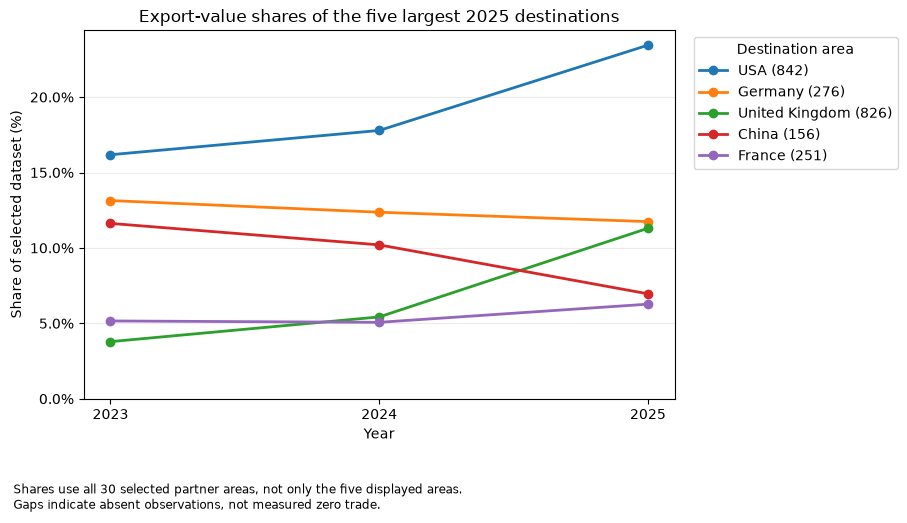

In [40]:
if ANALYZE_PARTNERS:
    import matplotlib.pyplot as plt
    from matplotlib.ticker import PercentFormatter

    partner_share_table = pd.DataFrame(partner_year_rows)
    fig_partner_shares, ax_partner_shares = plt.subplots(figsize=(9.2, 5.2))
    for partner in top5_partners_2025:
        partner_plot = partner_share_table.loc[
            partner_share_table["destinationCode"] == partner["destinationCode"]
        ].set_index("year").reindex(PARTNER_ANALYSIS_YEARS)
        ax_partner_shares.plot(
            PARTNER_ANALYSIS_YEARS, partner_plot["sharePercent"],
            marker="o", linewidth=2,
            label=f"{partner['destinationName']} ({partner['destinationCode']})"
        )
    ax_partner_shares.set_title("Switzerland: destination shares, 2023–2025\nFive largest 2025 destinations")
    ax_partner_shares.set_xlabel("Year")
    ax_partner_shares.set_ylabel("Share of selected dataset (%)")
    ax_partner_shares.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax_partner_shares.set_ylim(bottom=0)
    ax_partner_shares.grid(axis="y", alpha=0.25)
    ax_partner_shares.legend(title="Destination area", loc="upper left", bbox_to_anchor=(1.02, 1))
    fig_partner_shares.text(
        0.02, 0.01,
        "Standard HS4 export value across all 30 selected partner areas, not only the five displayed.\n"
        "Shares do not represent all Swiss exports. Gaps indicate absent observations, not measured zero trade.",
        fontsize=8.5
    )
    fig_partner_shares.tight_layout(rect=(0, 0.11, 1, 1))
    plt.show()

**Interpretation:** Selected export value rises from USD 388.0 billion in 2023 to USD 516.8 billion in 2025.
The USA leads in 2025 with USD 121.1 billion and a 23.44% share.
The United Kingdom gains 7.51 percentage points, the largest gain among the displayed five.
China loses 4.67 points; Germany loses 1.40 points.

**Limitation:** Share changes do not necessarily indicate changes in absolute value.
Retrospective selection limits generalization.
Current-USD changes can reflect prices, exchange rates, quantities, and product mix.
These comparisons establish neither physical-volume growth nor causation.


## Top ten HS4 headings in 2025

**Question:** Which HS4 headings have the highest 2025 export value across the 30 selected partner areas?

**Purpose:** Identify headings that dominate nominal export value.

**Method:** Rank all standard HS4 observations in 2025, not the earlier top-50 drill-down.
Calculate the full annual denominator before selecting ten headings.

::: {.content-hidden when-format="pdf"}

## Top 10 HS4 export headings in 2025

**Question:** Which HS4 headings have the highest 2025 export value across the 30 selected partner areas?

The ranking identifies headings that dominate nominal value and deserve closer examination.
Use the full saved standard-HS4 dataset, not the earlier three-year top-50 subset.
MongoDB calculates the annual total, product ranking, dataset shares, and display values in USD billions.
The share denominator includes all standard headings, not only the ten displayed headings.
These are nominal current-US-dollar values, not physical quantities or all Swiss exports.

`verify` and `rebuild` enable both product analyses after the partner-analysis checks.
The cells reuse the configured connection, clean collection, scope, and top-five selection.
The default offline run skips these analyses; the submitted saved outputs record the completed original run.

:::


In [49]:
ANALYZE_HS4_2025 = CONNECT_TO_MONGODB
ANALYZE_HS2_COMPOSITION = CONNECT_TO_MONGODB
PRODUCT_ANALYSIS_YEAR = "2025"
hs4_2025_checked = False
composition_2025_checked = False

if ANALYZE_HS4_2025 or ANALYZE_HS2_COMPOSITION:
    if not globals().get("CONNECT_TO_MONGODB", False):
        raise ValueError("Use the existing MongoDB connection before product analysis.")
    if "partner_analysis_filter" not in globals() or "collection_clean" not in globals():
        raise ValueError("Run the first partner-analysis setup before these sections.")
    if db.name != DB_NAME or collection_clean.name != "trade_clean" or collection_clean.database != db:
        raise ValueError("Use the configured database's trade_clean collection for product analysis.")
    product_2025_filter = partner_analysis_filter.copy()
    product_2025_filter["year"] = PRODUCT_ANALYSIS_YEAR
    if collection_clean.count_documents({}) != 72369:
        raise ValueError("The clean collection must retain 72,369 standard HS4 observations.")
    if collection_clean.count_documents(product_2025_filter) != 24376:
        raise ValueError("The 2025 scope must contain 24,376 standard HS4 observations.")
    match_products_2025 = {"$match": product_2025_filter}

if ANALYZE_HS2_COMPOSITION:
    if not globals().get("partner_shares_checked", False) or "top5_partners_2025" not in globals():
        raise ValueError("Run the first analysis's annual checks and 2025 top-five selection first.")
    if PARTNER_RANK_YEAR != PRODUCT_ANALYSIS_YEAR:
        raise ValueError("Reuse the five largest 2025 destinations, not another ranking year.")
    composition_partner_codes = top5_partner_codes.copy()
    if (len(composition_partner_codes) != 5 or len(set(composition_partner_codes)) != 5
            or composition_partner_codes != [row["destinationCode"] for row in top5_partners_2025]):
        raise ValueError("Reuse the same five distinct destination codes from the first analysis.")
    if "quality_snapshot" not in globals():
        raise ValueError("Keep the frozen H6 reference from the data quality setup in this session.")
    chapter_names = {
        row["id"]: row["text"].split(" - ", 1)[-1]
        for row in quality_snapshot["heading_reference"]["data"]["results"]
        if isinstance(row.get("id"), str) and len(row["id"]) == 2
    }
    leading_chapter_codes = []

if not ANALYZE_HS4_2025 and not ANALYZE_HS2_COMPOSITION:
    print("Product analyses disabled. No database access in these sections.")

MongoDB first calculates the annual total with `$group` and `$sum`.
It then groups by HS4 code, sorts by value, breaks ties by code, and limits display to ten.
`$first` retains each heading's consistent source description.
`$project` calculates USD billions and shares using the complete annual denominator.
Python passes that MongoDB total into the ranking without recalculating it.

**Pipeline excerpt:** The following statements retain the full denominator and the MongoDB ranking.
The full executable cell also checks the denominator and formats shortened labels.

```python
group_product_year_total = {"$group": {
    "_id": None, "totalValueUSD": {"$sum": "$tradeMeasures.primaryValueUSD"},
    "observations": {"$sum": 1}
}}
pipeline = [match_products_2025, group_product_year_total]
product_year_totals = list(collection_clean.aggregate(pipeline))
product_2025_total_usd = product_year_totals[0]["totalValueUSD"]
group_hs4_2025 = {"$group": {
    "_id": "$product.hsCode", "description": {"$first": "$product.description"},
    "valueUSD": {"$sum": "$tradeMeasures.primaryValueUSD"},
    "observations": {"$sum": 1}
}}
sort_hs4_2025 = {"$sort": {"valueUSD": -1, "_id": 1}}
limit_top10_hs4 = {"$limit": 10}
project_hs4_2025 = {"$project": {
    "_id": 0, "hsCode": "$_id", "description": 1, "valueUSD": 1, "observations": 1,
    "valueUSDbn": {"$divide": ["$valueUSD", 1e9]},
    "datasetSharePct": {"$multiply": [{"$divide": ["$valueUSD", product_2025_total_usd]}, 100]}
}}
pipeline = [match_products_2025, group_hs4_2025, sort_hs4_2025, limit_top10_hs4, project_hs4_2025]
top10_hs4_rows = list(collection_clean.aggregate(pipeline))
```

**Result:** The saved table and chart shorten labels, not codes or calculated values.


In [50]:
if ANALYZE_HS4_2025:
    from textwrap import shorten

    hs4_2025_checked = False
    group_product_year_total = {"$group": {
        "_id": None, "totalValueUSD": {"$sum": "$tradeMeasures.primaryValueUSD"},
        "observations": {"$sum": 1}
    }}
    pipeline = [match_products_2025, group_product_year_total]
    product_year_totals = list(collection_clean.aggregate(pipeline))
    if (not product_year_totals or product_year_totals[0]["observations"] != 24376
            or not math.isfinite(product_year_totals[0]["totalValueUSD"])
            or product_year_totals[0]["totalValueUSD"] <= 0):
        raise ValueError("Check the positive full-year total and 24,376 observations before ranking products.")
    product_2025_total_usd = product_year_totals[0]["totalValueUSD"]
    group_hs4_2025 = {"$group": {
        "_id": "$product.hsCode", "description": {"$first": "$product.description"},
        "valueUSD": {"$sum": "$tradeMeasures.primaryValueUSD"},
        "observations": {"$sum": 1}
    }}
    sort_hs4_2025 = {"$sort": {"valueUSD": -1, "_id": 1}}
    limit_top10_hs4 = {"$limit": 10}
    project_hs4_2025 = {"$project": {
        "_id": 0, "hsCode": "$_id", "description": 1, "valueUSD": 1, "observations": 1,
        "valueUSDbn": {"$divide": ["$valueUSD", 1e9]},
        "datasetSharePct": {"$multiply": [{"$divide": ["$valueUSD", product_2025_total_usd]}, 100]}
    }}
    pipeline = [match_products_2025, group_hs4_2025, sort_hs4_2025, limit_top10_hs4, project_hs4_2025]
    top10_hs4_rows = list(collection_clean.aggregate(pipeline))
    if len(top10_hs4_rows) != 10 or any(row["hsCode"] not in quality_heading_codes for row in top10_hs4_rows):
        raise ValueError("Expected ten standard HS4 headings from the full 2025 dataset.")
    top10_hs4 = pd.DataFrame(top10_hs4_rows)
    top10_hs4_display = top10_hs4[["hsCode", "description", "valueUSDbn", "datasetSharePct"]].copy()
    top10_hs4_display["description"] = [shorten(text, width=36, placeholder="…") for text in top10_hs4_display["description"]]
    top10_hs4_display = top10_hs4_display.rename(columns={
        "hsCode": "HS4", "description": "Product (short label)",
        "valueUSDbn": "Value (USD bn)", "datasetSharePct": "Dataset share (%)"
    })
    print(top10_hs4_display.to_string(index=False, formatters={
        "Value (USD bn)": "{:.2f}".format, "Dataset share (%)": "{:.2f}".format
    }))
    hs4_2025_checked = True

 HS4               Product (short label) Value (USD bn) Dataset share (%)
7108   Gold (including gold plated with…         191.64             37.09
3002      Human blood; animal blood for…          62.99             12.19
3004 Medicaments; (not goods of heading…          44.91              8.69
2933        Heterocyclic compounds with…          34.94              6.76
9102     Wrist-watches, pocket-watches,…          16.09              3.11
7113       Jewellery articles and parts…          14.35              2.78
9101     Wrist-watches, pocket-watches,…          10.51              2.03
9021  Orthopaedic appliances; including…           7.21              1.40
2716                   Electrical energy           4.48              0.87
9018 Instruments and appliances used in…           4.29              0.83


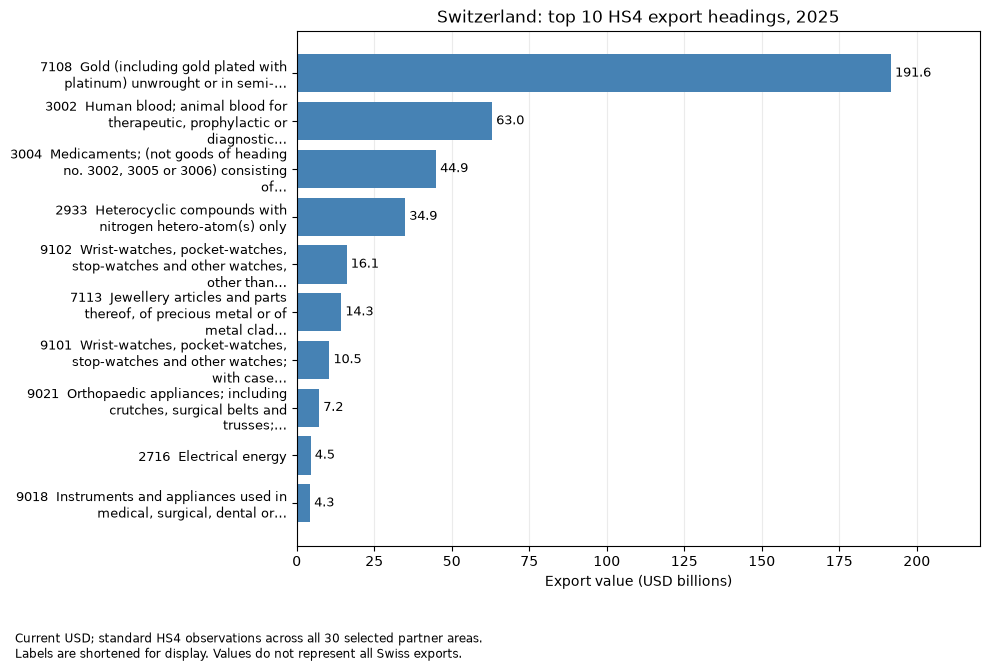

In [51]:
if ANALYZE_HS4_2025:
    import matplotlib.pyplot as plt
    from textwrap import fill, shorten

    if not hs4_2025_checked:
        raise ValueError("Run the HS4 ranking cell successfully before plotting.")
    hs4_plot_labels = [
        code + "  " + fill(shorten(description, width=74, placeholder="…"), width=35)
        for code, description in zip(top10_hs4["hsCode"], top10_hs4["description"])
    ]
    fig_hs4_2025, ax_hs4_2025 = plt.subplots(figsize=(10, 6.7))
    hs4_bars = ax_hs4_2025.barh(hs4_plot_labels, top10_hs4["valueUSDbn"], color="steelblue")
    ax_hs4_2025.invert_yaxis()
    ax_hs4_2025.bar_label(hs4_bars, fmt="%.1f", padding=3, fontsize=9)
    ax_hs4_2025.set_title("Switzerland: top 10 HS4 export headings, 2025")
    ax_hs4_2025.set_xlabel("Export value (USD billions)")
    ax_hs4_2025.tick_params(axis="y", labelsize=9)
    ax_hs4_2025.margins(x=0.15)
    ax_hs4_2025.set_xlim(left=0)
    ax_hs4_2025.set_axisbelow(True)
    ax_hs4_2025.grid(axis="x", alpha=0.25)
    fig_hs4_2025.text(
        0.02, 0.01,
        "Current USD; standard HS4 observations across all 30 selected partner areas.\n"
        "Labels are shortened for display. Values do not represent all Swiss exports.",
        fontsize=8.5
    )
    fig_hs4_2025.tight_layout(rect=(0, 0.09, 1, 1))
    plt.show()

**Interpretation:** Gold (7108) leads with USD 191.64 billion and 37.09% of selected 2025 value.
Heading 3002 follows at 12.19%; medicaments under 3004 account for 8.69%.
Heading 3002 includes blood, immunological products, vaccines, and related goods.
Heading 9101 covers precious-metal or precious-metal-clad watch cases; 9102 covers other watches.

**Limitation:** The top ten need not sum to 100%; other headings remain in the denominator.
Value rankings do not establish Swiss production origin, profitability, or physical-volume growth.


## HS2 composition of the same five partner areas

**Question:** How do the five largest 2025 partner areas differ in their HS2 product composition?

**Purpose:** Compare broad product mixes using common chapter categories.

**Method:** Group all standard HS4 observations by `product.chapter.hsCode`.
Choose five chapters by combined value across the same five partner areas.
Do not restrict totals to the top-ten or top-50 headings.
The saved H6 reference supplies labels after MongoDB aggregation without another download.


In [52]:
if ANALYZE_HS2_COMPOSITION:
    composition_2025_checked = False
    leading_chapter_codes = []
    composition_filter = product_2025_filter.copy()
    composition_filter["destinationArea.comtradeCode"] = {"$in": composition_partner_codes}
    match_composition_2025 = {"$match": composition_filter}
    group_partner_chapters = {"$group": {
        "_id": {"destinationCode": "$destinationArea.comtradeCode", "chapterCode": "$product.chapter.hsCode"},
        "destinationName": {"$first": "$destinationArea.name"},
        "valueUSD": {"$sum": "$tradeMeasures.primaryValueUSD"}, "observations": {"$sum": 1}
    }}
    composition_base_pipeline = [match_composition_2025, group_partner_chapters]
    group_leading_chapters = {"$group": {"_id": "$_id.chapterCode", "valueUSD": {"$sum": "$valueUSD"}}}
    sort_leading_chapters = {"$sort": {"valueUSD": -1, "_id": 1}}
    limit_leading_chapters = {"$limit": 5}
    pipeline = composition_base_pipeline + [group_leading_chapters, sort_leading_chapters, limit_leading_chapters]
    leading_chapter_rows = list(collection_clean.aggregate(pipeline))
    if len(leading_chapter_rows) != 5 or any(row["_id"] not in chapter_names for row in leading_chapter_rows):
        raise ValueError("Expected five HS2 chapters with labels in the saved H6 reference.")
    leading_chapter_codes = [row["_id"] for row in leading_chapter_rows]

`$cond` assigns observed chapters outside the common five to Other.
Further `$group` stages calculate category values and each partner area's full denominator.
`$push` and `$unwind` retain category rows beside their partner total.
That total repeats across categories; summing it would double-count value.

**Pipeline excerpt:** The following statements show the category grouping, complete partner totals, and share calculation.
The full executable cell also reconciles values and counts, checks 100% totals, and formats the table.
The saved confirmation follows the table; the PDF omits the Python checks and formatting code, not their execution.

```python
group_display_categories = {"$group": {
    "_id": {
        "destinationCode": "$_id.destinationCode",
        "categoryCode": {"$cond": [
            {"$in": ["$_id.chapterCode", leading_chapter_codes]}, "$_id.chapterCode", "Other"
        ]}
    },
    "destinationName": {"$first": "$destinationName"},
    "valueUSD": {"$sum": "$valueUSD"}, "observations": {"$sum": "$observations"}
}}
group_composition_totals = {"$group": {
    "_id": "$_id.destinationCode", "destinationName": {"$first": "$destinationName"},
    "partnerValueUSD": {"$sum": "$valueUSD"},
    "categories": {"$push": {
        "categoryCode": "$_id.categoryCode", "valueUSD": "$valueUSD", "observations": "$observations"
    }}
}}
unwind_composition_categories = {"$unwind": "$categories"}
project_composition_shares = {"$project": {
    "_id": 0, "destinationCode": "$_id", "destinationName": 1, "partnerValueUSD": 1,
    "categoryCode": "$categories.categoryCode", "valueUSD": "$categories.valueUSD",
    "observations": "$categories.observations",
    "sharePercent": {"$multiply": [{"$divide": ["$categories.valueUSD", "$partnerValueUSD"]}, 100]}
}}
sort_composition_shares = {"$sort": {"destinationCode": 1, "categoryCode": 1}}
composition_share_pipeline = composition_base_pipeline + [
    group_display_categories, group_composition_totals,
    unwind_composition_categories, project_composition_shares, sort_composition_shares
]
pipeline = composition_share_pipeline
composition_share_rows = list(collection_clean.aggregate(pipeline))
```

**Result:** Full-precision category shares total 100% for each area.
Values and observation counts match the first analysis's 2025 results.
A dash means no recorded category observation, not measured zero trade.
Other combines observed values; it does not create absent observations.


In [53]:
if ANALYZE_HS2_COMPOSITION:
    composition_2025_checked = False
    if len(leading_chapter_codes) != 5:
        raise ValueError("Run the common-chapter selection before calculating composition.")
    group_display_categories = {"$group": {
        "_id": {
            "destinationCode": "$_id.destinationCode",
            "categoryCode": {"$cond": [
                {"$in": ["$_id.chapterCode", leading_chapter_codes]}, "$_id.chapterCode", "Other"
            ]}
        },
        "destinationName": {"$first": "$destinationName"},
        "valueUSD": {"$sum": "$valueUSD"}, "observations": {"$sum": "$observations"}
    }}
    group_composition_totals = {"$group": {
        "_id": "$_id.destinationCode", "destinationName": {"$first": "$destinationName"},
        "partnerValueUSD": {"$sum": "$valueUSD"},
        "categories": {"$push": {
            "categoryCode": "$_id.categoryCode", "valueUSD": "$valueUSD", "observations": "$observations"
        }}
    }}
    unwind_composition_categories = {"$unwind": "$categories"}
    project_composition_shares = {"$project": {
        "_id": 0, "destinationCode": "$_id", "destinationName": 1, "partnerValueUSD": 1,
        "categoryCode": "$categories.categoryCode", "valueUSD": "$categories.valueUSD",
        "observations": "$categories.observations",
        "sharePercent": {"$multiply": [{"$divide": ["$categories.valueUSD", "$partnerValueUSD"]}, 100]}
    }}
    sort_composition_shares = {"$sort": {"destinationCode": 1, "categoryCode": 1}}
    composition_share_pipeline = composition_base_pipeline + [
        group_display_categories, group_composition_totals,
        unwind_composition_categories, project_composition_shares, sort_composition_shares
    ]
    pipeline = composition_share_pipeline
    composition_share_rows = list(collection_clean.aggregate(pipeline))
    group_composition_checks = {"$group": {
        "_id": "$destinationCode", "partnerValueUSD": {"$first": "$partnerValueUSD"},
        "sharePercentTotal": {"$sum": "$sharePercent"}, "observations": {"$sum": "$observations"}
    }}
    pipeline = composition_share_pipeline + [group_composition_checks, {"$sort": {"_id": 1}}]
    composition_scope_rows = list(collection_clean.aggregate(pipeline))
    if {row["_id"] for row in composition_scope_rows} != set(composition_partner_codes):
        raise ValueError("The composition must retain the original five destinations.")
    expected_partner_totals = {row["destinationCode"]: row for row in top5_partners_2025}
    for row in composition_scope_rows:
        expected = expected_partner_totals[row["_id"]]
        if (not math.isclose(row["sharePercentTotal"], 100, abs_tol=1e-8)
                or not math.isclose(row["partnerValueUSD"], expected["valueUSD"], rel_tol=1e-12, abs_tol=0.01)
                or row["observations"] != expected["observations"]):
            raise ValueError("Composition shares, totals, or counts differ from the first analysis.")
    composition_share_table = pd.DataFrame(composition_share_rows)
    composition_category_codes = leading_chapter_codes + ["Other"]
    composition_matrix = composition_share_table.pivot(
        index="destinationCode", columns="categoryCode", values="sharePercent"
    ).reindex(index=composition_partner_codes, columns=composition_category_codes)
    composition_destination_names = {row["destinationCode"]: row["destinationName"] for row in top5_partners_2025}
    composition_display = composition_matrix.rename(
        index=composition_destination_names,
        columns={code: ("Other" if code == "Other" else "HS2 " + code) for code in composition_category_codes}
    )
    composition_display.index.name = "Destination area"
    composition_display.columns.name = "Share (%)"
    print(composition_display.to_string(na_rep="—", float_format="{:.1f}".format))
    print("Category shares total 100% and partner values/counts match the first analysis.")
    composition_2025_checked = True

Share (%)         HS2 71  HS2 30  HS2 84  HS2 91  HS2 90  Other
Destination area                                               
USA                 47.3    33.3     2.6     4.3     3.7    8.9
Germany             13.3    21.1     9.4     2.4     6.2   47.6
United Kingdom      83.6     4.1     1.6     3.6     0.9    6.2
China               52.7    20.6     6.2     6.1     4.6    9.9
France              55.5     9.7     4.4     5.0     2.7   22.7
Category shares total 100% and partner values/counts match the first analysis.


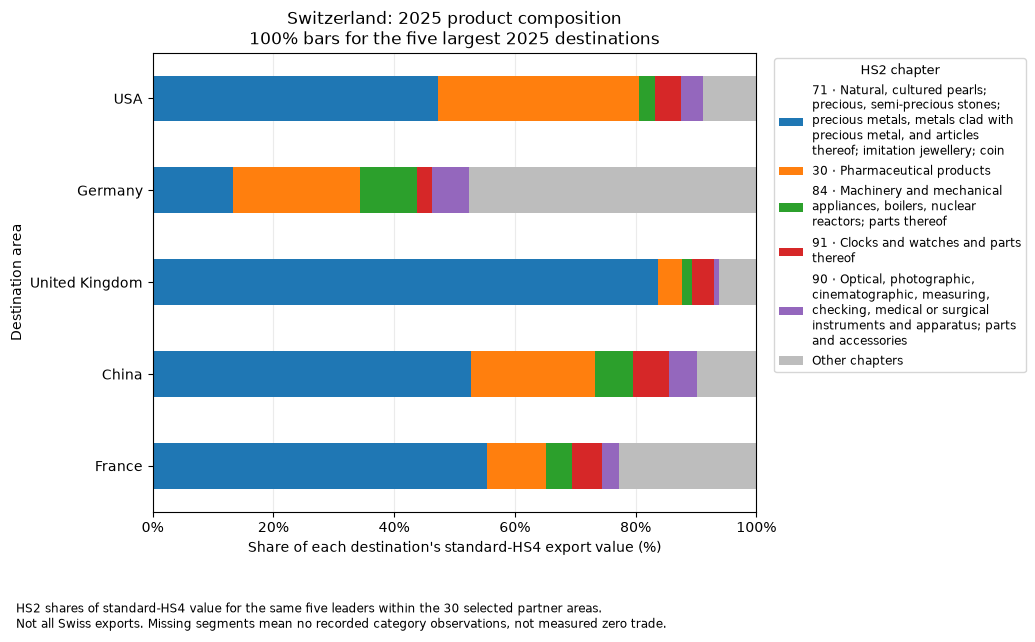

In [54]:
if ANALYZE_HS2_COMPOSITION:
    import matplotlib.pyplot as plt
    from matplotlib.ticker import PercentFormatter
    from textwrap import fill

    if not composition_2025_checked:
        raise ValueError("Run the composition share checks successfully before plotting.")
    composition_matrix = pd.DataFrame(composition_share_rows).pivot(
        index="destinationCode", columns="categoryCode", values="sharePercent"
    ).reindex(index=composition_partner_codes, columns=composition_category_codes)
    composition_plot = composition_matrix.rename(index=composition_destination_names)
    chapter_colors = [plt.get_cmap("tab10")(index) for index in range(len(leading_chapter_codes))] + ["#bdbdbd"]
    fig_composition_2025, ax_composition_2025 = plt.subplots(figsize=(10.5, 6.4))
    composition_plot.plot.barh(stacked=True, ax=ax_composition_2025, color=chapter_colors)
    ax_composition_2025.invert_yaxis()
    ax_composition_2025.set_xlim(0, 100)
    ax_composition_2025.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax_composition_2025.set_title("Switzerland: 2025 product composition\n100% bars for the five largest 2025 destinations")
    ax_composition_2025.set_xlabel("Share of each destination's standard-HS4 export value (%)")
    ax_composition_2025.set_ylabel("Destination area")
    legend_labels = [
        "Other chapters" if code == "Other" else fill(code + " · " + chapter_names[code], width=34)
        for code in composition_category_codes
    ]
    handles, labels = ax_composition_2025.get_legend_handles_labels()
    ax_composition_2025.legend(
        handles, legend_labels, title="HS2 chapter", loc="upper left",
        bbox_to_anchor=(1.02, 1), fontsize=8.5, title_fontsize=9
    )
    ax_composition_2025.set_axisbelow(True)
    ax_composition_2025.grid(axis="x", alpha=0.25)
    fig_composition_2025.text(
        0.02, 0.01,
        "HS2 shares of standard-HS4 value for the same five leaders within the 30 selected partner areas.\n"
        "Not all Swiss exports. Missing segments mean no recorded category observations, not measured zero trade.",
        fontsize=8.5
    )
    fig_composition_2025.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()

**Interpretation:** Chapter 71 accounts for 83.6% of the United Kingdom's selected value.
This chapter includes precious metals, stones, and jewellery, not gold alone.
Pharmaceutical products (30) account for 33.3% of the USA's mix and 21.1% of Germany's.
Germany has the largest Other share, at 47.6%.

**Limitation:** Other hides chapter detail and does not measure diversification.
Equal bar lengths compare percentages, not equal export values.
Rounding can produce displayed totals of 99.9% or 100.1%; checks use full precision.
Never add HS2 totals to their child-heading values.


```{=latex}
\clearpage
```

# Conclusions

## Answers and practical relevance

1. The USA leads selected 2025 value with 23.44%.
   Germany, the United Kingdom, China, and France complete the five largest partner areas.
   The United Kingdom gains the most share among these five: 7.51 percentage points since 2023.
   The USA gains 7.26 points; China loses 4.67 points.
   These comparisons identify areas for further market research, not predictions of demand or country risk.
2. Gold (7108) leads the HS4 ranking with 37.09%, followed by 3002 at 12.19% and 3004 at 8.69%.
   High nominal values identify product groups for investigation, not shipment volumes or profitability.
3. The five areas have different chapter mixes.
   Chapter 71 dominates the United Kingdom; pharmaceuticals contribute substantially to the USA and Germany.
   Germany's 47.6% Other share leaves more chapter detail outside the five common categories.
   These comparisons guide follow-up questions, not commercial recommendations or explanations of earlier share changes.


```{=latex}
\clearpage
```

# Learnings

1. **Modeling around queries.** I learned to choose embedding or references from the queries I need.
   Embedding keeps related details together but repeats labels; references separate entities and may require joins.
   Here, one trade observation embeds partner-area, product, measurement, and quality details.
2. **Identifiers and collections.** I learned that `_id` uniquely identifies a document within its collection.
   An HS4 code alone cannot identify an observation across different years and partner areas.
   Stable identifiers let upserts replace matching observations instead of creating duplicates.
3. **Flexible schemas and BSON types.** MongoDB's flexible schema does not remove the need for consistent fields and BSON types.
   I kept HS codes as strings to preserve leading zeros.
   I used `$type` to distinguish missing fields, nulls, and numeric values.
4. **Aggregation stages and order.** I learned to build aggregations as ordered stages.
   `$match` filters observations, `$project` shapes documents, and `$group` calculates summaries.
   I calculated full denominators before `$sort` and `$limit` selected display rows.
5. **Grouping and arrays.** I learned that grouping and unwinding change what one pipeline document represents.
   `$push` collects results into arrays; `$unwind` returns one document per array element.
   I avoided summing repeated annual totals after unwinding partner results.
6. **Transformations and database writes.** I learned that transforming query results differs from changing stored data.
   `$project` and `$addFields` reshape pipeline results; `$out` writes them and can replace an existing collection.
   I kept raw evidence separate, checked the destination, and verified the saved collection.


# Sources

- UN Comtrade, [API documentation](https://comtradeplus.un.org/ApiDocs): the source API for annual Swiss export observations and query parameters.
- UN Comtrade, [H6 classification reference](https://comtradeapi.un.org/files/v1/app/reference/H6.json) and [partner-area reference](https://comtradeapi.un.org/files/v1/app/reference/partnerAreas.json): heading membership, partner codes, and official labels.
- MongoDB, [Data Modeling](https://www.mongodb.com/docs/manual/data-modeling/): document structure, embedded objects, and references.
- MongoDB, [aggregation stages](https://www.mongodb.com/docs/manual/reference/operator/aggregation-pipeline/), [`$out`](https://www.mongodb.com/docs/manual/reference/operator/aggregation/out/), and [`$substrBytes`](https://www.mongodb.com/docs/manual/reference/operator/aggregation/substrBytes/): pipeline operations, collection writes, and chapter-prefix derivation.
- MongoDB, [PyMongo aggregation guide](https://www.mongodb.com/docs/languages/python/pymongo-driver/current/aggregation/): executing MongoDB aggregation pipelines from Python.
- UN Comtrade, [Data Use and Re-dissemination](https://uncomtrade.org/docs/re-dissemination-of-data/): conditions to check before sharing source observations.

## Frozen data and result provenance

The analytical input is `data/v2_hs4_snapshot_20261017T094752738553Z.json`, including HS4 observations, the H6 reference, partner selection, and extraction logs.
Historical discovery uses `data/v2_partner_totals_20261016T143600945247Z.json`.
This separate snapshot contains all-commodity `TOTAL` observations, not HS2 product detail.

The saved MongoDB outputs in this notebook support the reported counts, rankings, shares, and verification results.
UN Comtrade may revise data after the frozen extraction.


::: {.content-hidden when-format="pdf"}

# PDF export and final submission checklist

The first Markdown cell contains Quarto YAML settings.
Quarto supplies the title, table of contents, and section numbering.
The export command uses saved outputs without executing Python cells.

Render V3 from this notebook's folder with:

```bash
quarto render "UN_Comtrade_V3.ipynb" --to pdf --no-execute
```

The notebook now contains saved clean-model checks, three executed analyses, conclusions, learnings, and model images.
These sections do not replace the remaining submission checks:

1. Review the conclusions and learnings against the saved results and personal experience.
2. Add the submission author and record the package versions and MongoDB server version used.
3. Follow the reproduction guide on a notebook copy, using frozen snapshots and your own MongoDB connection.
   Choose `RUN_MODE` before restarting the kernel; keep write approval disabled outside an isolated rebuild.
   Do not rerun extraction or saving merely to export the PDF.
4. Check stale display labels, credentials, errors, clipped tables/code, and all local image paths.
5. Render and inspect every PDF page, including the complete UML and schema comparison images.
6. Package the PDF, saved V3 notebook, and required images in the ILIAS ZIP.
   Exclude `.env`, unrelated notebooks, and unused data.
   Check course upload rules and UN Comtrade distribution terms before including snapshot files.

The earlier PDF remains a draft until a new export passes the final readability checks.

:::
